# 2026 CITS4012 Project
**Group 5 — TweetQA**

# Readme

Run cells in order. All implementation code is in this notebook. `submission_support.zip` contains only the assignment data, saved logs, predictions, metrics and attention figures—no implementation code.

Upload that ZIP when prompted, or put its public Google Drive file ID in `SUPPORT_FILE_ID`. Model weights are loaded only if optional validation inference is enabled. Training and fresh test prediction are disabled. Default execution displays saved experimental outputs and verifies recorded ROUGE-L, EM and F1; set `RESCORE_ALL_METRICS=True` to also recalculate BLEU-1/METEOR (requires NLTK/WordNet).

B3/B4 have completed validation experiments but their fine-tuned weights/final test results are pending. Do not substitute validation scores in the final-test table. Keep this status consistent with the report.

# 1.Dataset Processing

In [1]:
SUPPORT_FILE_ID = ""  # Public Google Drive file ID; leave blank to upload submission_support.zip.
RUN_VALIDATION_INFERENCE = False
RESCORE_ALL_METRICS = False

import os,sys,json,csv,hashlib,zipfile,tempfile,statistics,subprocess
from pathlib import Path
from collections import Counter
import numpy as np
import torch
from IPython.display import display,Markdown,Image

archive=Path("submission_support.zip").resolve()
if SUPPORT_FILE_ID:
    subprocess.check_call([sys.executable,"-m","pip","install","-q","gdown"])
    import gdown
    gdown.download(id=SUPPORT_FILE_ID,output=str(archive),quiet=False)
elif not archive.exists():
    from google.colab import files
    uploaded=files.upload()
    assert "submission_support.zip" in uploaded
    archive.write_bytes(uploaded["submission_support.zip"])
assert hashlib.sha256(archive.read_bytes()).hexdigest()=='de42ed18be0d9f6bb9ed242f556bc6cb9222f59197b3d64176a57324aef71c55',"Supporting files differ"
WORK=Path(tempfile.mkdtemp(prefix="group5_submission_"))
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None
    for name in z.namelist():assert not Path(name).is_absolute() and ".." not in Path(name).parts
    z.extractall(WORK)
os.chdir(WORK)
for name,digest in json.loads(Path("support_manifest.json").read_text()).items():
    assert hashlib.sha256(Path(name).read_bytes()).hexdigest()==digest,name
Path("src/baselines").mkdir(parents=True,exist_ok=True)
os.environ["TWEETQA_DIR"]=str(WORK/"data")
os.environ["A2_RESULTS"]=str(WORK/"new_runtime_results")
os.environ["A2_CKPT"]=str(WORK/"new_runtime_checkpoints")
print("Group 5 | PyTorch",torch.__version__,"| Supporting files verified")


Group 5 | PyTorch 2.14.0 | Supporting files verified


### Data loading, tokenisation, tweet features, silver spans and batching

In [2]:
%%writefile src/__init__.py
# package marker


Writing src/__init__.py


In [3]:
%%writefile src/baselines/__init__.py
# package marker


Writing src/baselines/__init__.py


In [4]:
%%writefile src/evaluate.py
"""Evaluation metrics for TweetQA.

Every metric is computed per example as the max over the gold answers,
and corpus scores are the mean x 100.

- BLEU-1: nltk sentence_bleu, weights (1,0,0,0), smoothing method1
- METEOR: nltk meteor_score (needs WordNet)
- ROUGE-L: our own LCS implementation, F-measure with beta = 1.2 (the
  coco-caption convention used by the official TweetQA evaluation)
- EM and token-F1: SQuAD-style, computed on normalised text
"""
import re
import string
import unicodedata
from collections import Counter

METRICS = ("bleu1", "meteor", "rougeL", "em", "f1")
_ARTICLES = re.compile(r"\b(a|an|the)\b")
_nltk_ready = False


def _ensure_nltk():
    global _nltk_ready
    if _nltk_ready:
        return
    import nltk
    for pkg, path in [("wordnet", "corpora/wordnet"), ("omw-1.4", "corpora/omw-1.4")]:
        try:
            nltk.data.find(path)
        except LookupError:
            nltk.download(pkg, quiet=True)
    _nltk_ready = True


def normalize_answer(s):
    """Lowercase, replace ASCII and Unicode punctuation with spaces,
    drop articles, collapse whitespace."""
    s = s.lower()
    s = "".join(" " if (ch in string.punctuation or unicodedata.category(ch).startswith("P")) else ch
                for ch in s)
    s = _ARTICLES.sub(" ", s)
    return " ".join(s.split())


def norm_tokens(s):
    return normalize_answer(s).split()


# ---------------------------------------------------------------- metrics

def exact_match(pred, gold):
    return float(normalize_answer(pred) == normalize_answer(gold))


def token_f1(pred, gold):
    p, g = norm_tokens(pred), norm_tokens(gold)
    if not p or not g:
        return float(p == g)
    common = Counter(p) & Counter(g)
    overlap = sum(common.values())
    if overlap == 0:
        return 0.0
    prec, rec = overlap / len(p), overlap / len(g)
    return 2 * prec * rec / (prec + rec)


def lcs_len(a, b):
    """Length of the longest common subsequence of two token lists (O(len(a)*len(b)) DP)."""
    if not a or not b:
        return 0
    prev = [0] * (len(b) + 1)
    for x in a:
        cur = [0] * (len(b) + 1)
        for j, y in enumerate(b, 1):
            cur[j] = prev[j - 1] + 1 if x == y else max(prev[j], cur[j - 1])
        prev = cur
    return prev[-1]


def rouge_l(pred, gold, beta=1.2):
    p, g = norm_tokens(pred), norm_tokens(gold)
    if not p or not g:
        return float(p == g and bool(p))
    lcs = lcs_len(p, g)
    if lcs == 0:
        return 0.0
    prec, rec = lcs / len(p), lcs / len(g)
    return (1 + beta ** 2) * prec * rec / (rec + beta ** 2 * prec)


def bleu1(pred, gold):
    from nltk.translate.bleu_score import SmoothingFunction, sentence_bleu
    p, g = norm_tokens(pred), norm_tokens(gold)
    if not p or not g:
        return 0.0
    return sentence_bleu([g], p, weights=(1, 0, 0, 0),
                         smoothing_function=SmoothingFunction().method1)


def meteor(pred, gold):
    _ensure_nltk()
    from nltk.translate.meteor_score import meteor_score
    p, g = norm_tokens(pred), norm_tokens(gold)
    if not p or not g:
        return 0.0
    return meteor_score([g], p)


_FUNCS = {"bleu1": bleu1, "meteor": meteor, "rougeL": rouge_l, "em": exact_match, "f1": token_f1}


def score_example(pred, golds, metrics=METRICS):
    """Per-example scores in [0, 1]: max over gold answers."""
    pred = pred or ""
    return {m: max(_FUNCS[m](pred, g) for g in golds) for m in metrics}


def evaluate(preds, golds_list, metrics=METRICS, return_per_example=False):
    """preds: list[str]; golds_list: list[list[str]]. Returns corpus scores (mean x 100)."""
    assert len(preds) == len(golds_list), (len(preds), len(golds_list))
    per = [score_example(p, g, metrics) for p, g in zip(preds, golds_list)]
    n = max(1, len(per))
    corpus = {m: 100.0 * sum(s[m] for s in per) / n for m in metrics}
    return (corpus, per) if return_per_example else corpus


def fmt(scores):
    return " ".join(f"{m}={scores[m]:.2f}" for m in METRICS if m in scores)


Writing src/evaluate.py


In [5]:
%%writefile src/data.py
"""TweetQA data pipeline: loading, splits, offset-preserving tokenisation,
tweet normalisation, token flags, silver-span labelling, vocabularies and
a padded DataLoader.

Design notes (see results/DATA_REPORT.md):
- test.csv is the original TweetQA dev set. It stays locked (TEST_LOCKED)
  until the final evaluation. Validation is 10% of train, grouped by tweet.
- Every token keeps its character offsets into the raw tweet, so a
  predicted span (i, j) maps back to tweet[start_i:end_j].
- The normaliser only changes the *word* used for the embedding lookup.
  The char-CNN always sees the raw (lowercased) token, so @handles stay
  distinguishable after @user -> <user>.
"""
import ast
import csv
import os
import random
import re
from collections import Counter, defaultdict
from pathlib import Path

import torch
from torch.utils.data import DataLoader, Dataset

try:
    from .evaluate import normalize_answer, rouge_l
except ImportError:  # inlined in the notebook / run as a script
    from evaluate import normalize_answer, rouge_l

TEST_LOCKED = True
DATA_DIR = Path(os.environ.get("TWEETQA_DIR", Path(__file__).resolve().parents[1] / "data"
                               if "__file__" in globals() else "data"))
SPLIT_SEED = 4012
VAL_FRAC = 0.10

# ------------------------------------------------------------------ loading

_ANSWER_ITEM = re.compile(r"'(?:[^'\\]|\\.)*'|\"(?:[^\"\\]|\\.)*\"", re.S)


def parse_answers(field):
    """The Answer column is a numpy-array repr: ['a' 'b'] (space/newline separated, mixed quotes)."""
    items = [ast.literal_eval(m) for m in _ANSWER_ITEM.findall(field)]
    if not items:
        raise ValueError(f"unparseable answer field: {field!r}")
    return [str(a) for a in items]


def _read_csv(name):
    with open(Path(DATA_DIR) / name, encoding="utf-8") as f:
        rows = list(csv.DictReader(f))
    return [dict(row_id=i, qid=r["qid"], question=r["Question"], tweet=r["Tweet"],
                 answers=parse_answers(r["Answer"]), answer_field=r["Answer"])
            for i, r in enumerate(rows)]


def _question_word(q):
    toks = tokenize(q.lower())
    w = toks[0][0] if toks else ""
    return w if w in {"what", "who", "how", "where", "why", "which", "when"} else "other"


def get_splits(seed=SPLIT_SEED, val_frac=VAL_FRAC):
    """Train/val from train.csv: exact duplicates dropped, grouped by tweet,
    stratified by the first question word of each tweet's first question."""
    rows, seen = [], set()
    for r in _read_csv("train.csv"):
        key = (r["question"], r["answer_field"], r["tweet"])
        if key not in seen:
            seen.add(key)
            rows.append(r)
    by_tweet = defaultdict(list)
    for r in rows:
        by_tweet[r["tweet"]].append(r)
    strata = defaultdict(list)
    for tweet in sorted(by_tweet):
        strata[_question_word(by_tweet[tweet][0]["question"])].append(tweet)
    rng = random.Random(seed)
    val_tweets = set()
    for s in sorted(strata):
        tweets = strata[s][:]
        rng.shuffle(tweets)
        val_tweets.update(tweets[:round(len(tweets) * val_frac)])
    train = [r for r in rows if r["tweet"] not in val_tweets]
    val = [r for r in rows if r["tweet"] in val_tweets]
    return train, val


def load_test():
    if TEST_LOCKED:
        raise RuntimeError("Test set is locked (TEST_LOCKED=True). It is used once, in Stage 8.")
    return _read_csv("test.csv")


# ------------------------------------------------------------- tokenisation

_URL = r"https?://\S+|www\.\S+"
_EMOJI_CHARS = "\U0001F000-\U0001FAFF☀-➿⬀-⯿️‍"
_TOKEN_RE = re.compile(
    rf"(?P<url>{_URL})"
    r"|(?P<mention>@\w+)"
    r"|(?P<hashtag>#\w+)"
    rf"|(?P<emoji>[{_EMOJI_CHARS}]+)"
    r"|(?P<number>\d+(?:[.,:/]\d+)*)"
    r"|(?P<word>\w+(?:['’]\w+)*)"
    r"|(?P<sym>[^\w\s])",
    re.UNICODE,
)
_ELONG = re.compile(r"(.)\1{2,}")


def tokenize(text):
    """Returns [(raw_token, start, end, kind)] with char offsets into text."""
    return [(m.group(0), m.start(), m.end(), m.lastgroup) for m in _TOKEN_RE.finditer(text)]


def normalise_tokens(raw_tokens, use_normaliser=True):
    """Map raw tokens to model tokens: dicts with word, raw, start, end, kind.

    Normaliser: @user -> <user>, url -> <url>, emoji -> <emoji>,
    #tag -> '#' + 'tag', elongation squashed to 2 repeats, lowercase.
    With use_normaliser=False the word is just the lowercased raw token.
    """
    out = []
    for raw, s, e, kind in raw_tokens:
        if not use_normaliser:
            out.append(dict(word=raw.lower(), raw=raw, start=s, end=e, kind=kind))
        elif kind == "mention":
            out.append(dict(word="<user>", raw=raw, start=s, end=e, kind=kind))
        elif kind == "url":
            out.append(dict(word="<url>", raw=raw, start=s, end=e, kind=kind))
        elif kind == "emoji":
            out.append(dict(word="<emoji>", raw=raw, start=s, end=e, kind=kind))
        elif kind == "hashtag":
            out.append(dict(word="#", raw="#", start=s, end=s + 1, kind=kind))
            tag = raw[1:]
            out.append(dict(word=_ELONG.sub(r"\1\1", tag.lower()), raw=tag, start=s + 1, end=e, kind=kind))
        else:
            out.append(dict(word=_ELONG.sub(r"\1\1", raw.lower()), raw=raw, start=s, end=e, kind=kind))
    return out


_BYLINE_RE = re.compile(r"\(@\w+\)\s+[A-Za-z]+\.?\s+\d{1,2},\s+\d{4}\s*$")
_BOUNDARY = {".", "!", "?", "—", "–", "-", "\"", "”", "|", ":"}


def byline_start(text, tokens):
    """Index of the first token of the trailing 'Name (@handle) Month D, YYYY'
    byline, or len(tokens) if there is none. The name is taken back to the
    previous sentence boundary, at most 6 tokens."""
    m = _BYLINE_RE.search(text)
    if not m:
        return len(tokens)
    k = next((i for i, t in enumerate(tokens) if t["start"] >= m.start()), len(tokens))
    j = k
    while j > 0 and k - j < 6 and tokens[j - 1]["raw"] not in _BOUNDARY:
        j -= 1
    return j


FLAG_NAMES = ("mention", "hashtag", "url", "emoji", "number", "capitalised", "in_byline", "in_other_seq")


def token_flags(tokens, other_words, byline_from=None):
    by = len(tokens) if byline_from is None else byline_from
    flags = []
    for i, t in enumerate(tokens):
        flags.append([
            float(t["kind"] == "mention"), float(t["kind"] == "hashtag"), float(t["kind"] == "url"),
            float(t["kind"] == "emoji"), float(t["kind"] == "number"),
            float(t["raw"][:1].isupper()), float(i >= by),
            float(t["word"] in other_words and t["word"] not in _STOP),
        ])
    return flags


_STOP = set("""a an the of to in on at for by with from and or but is are was were be been being am
do does did has have had i you he she it we they me him her us them my your his its our their this that
these those what who whom whose which when where why how not no yes so if than then there here as just
about into out up down over can will would should could may might must 's ? . , ! ' " - — : ; ( )""".split())


# ------------------------------------------------------------- silver spans

def _norm_toks(raw):
    return normalize_answer(raw).split()


def silver_spans(tokens, tweet, answers, max_len=15, tau=0.5):
    """Score every span (i, j), j - i < max_len, that starts and ends on a
    content token, by token-F1 against each gold answer (max over golds).

    Returns (best, best_f1, soft):
      best  : (i, j) with the highest F1, ties broken by ROUGE-L then length
      soft  : [(i, j, w)] for all spans with F1 >= tau, weights proportional to F1
    """
    ntok = [_norm_toks(t["raw"]) for t in tokens]
    content = [bool(x) for x in ntok]
    golds = [Counter(_norm_toks(a)) for a in answers]
    glens = [sum(g.values()) for g in golds]
    scored = []
    for i in range(len(tokens)):
        if not content[i]:
            continue
        bag, n = Counter(), 0
        for j in range(i, min(len(tokens), i + max_len)):
            bag.update(ntok[j])
            n += len(ntok[j])
            if not content[j]:
                continue
            f = 0.0
            for g, gl in zip(golds, glens):
                if gl == 0:
                    continue
                ov = sum((bag & g).values())
                if ov:
                    p, r = ov / n, ov / gl
                    f = max(f, 2 * p * r / (p + r))
            if f > 0:
                scored.append((f, i, j))
    if not scored:
        return None, 0.0, []
    top = max(f for f, _, _ in scored)
    ties = [(i, j) for f, i, j in scored if f == top]
    if len(ties) > 1:
        def key(ij):
            txt = tweet[tokens[ij[0]]["start"]:tokens[ij[1]]["end"]]
            return (max(rouge_l(txt, a) for a in answers), -(ij[1] - ij[0]), -ij[0])
        ties.sort(key=key, reverse=True)
    soft = [(i, j, f) for f, i, j in scored if f >= tau]
    z = sum(w for _, _, w in soft)
    soft = [(i, j, w / z) for i, j, w in soft]
    return ties[0], top, soft


def span_text(ex, i, j):
    return ex["tweet"][ex["t_tokens"][i]["start"]:ex["t_tokens"][j]["end"]]


# ------------------------------------------------------------------- vocab

class Vocab:
    PAD, UNK = "<pad>", "<unk>"

    def __init__(self, counter, min_freq=2, specials=()):
        self.itos = [self.PAD, self.UNK] + [s for s in specials if s not in (self.PAD, self.UNK)]
        self.itos += sorted([w for w, c in counter.items() if c >= min_freq and w not in self.itos],
                            key=lambda w: (-counter[w], w))
        self.stoi = {w: i for i, w in enumerate(self.itos)}

    def __len__(self):
        return len(self.itos)

    def __call__(self, w):
        return self.stoi.get(w, 1)


SPECIALS = ("<user>", "<url>", "<emoji>")
MAX_WORD_CHARS = 16


def build_vocabs(examples, min_freq=2, char_min_freq=5):
    """Vocabularies come from the training split only."""
    wc, cc = Counter(), Counter()
    for ex in examples:
        for t in ex["t_tokens"] + ex["q_tokens"]:
            wc[t["word"]] += 1
            cc.update(t["raw"].lower()[:MAX_WORD_CHARS])
    return Vocab(wc, min_freq, SPECIALS), Vocab(cc, char_min_freq)


# ----------------------------------------------------------------- encoding

# tau: an example is trainable if its best silver span has F1 >= tau.
# soft_tau: minimum F1 for a span to join the soft target set (None = same as tau). Kept separate so the
# soft-set width can be varied without changing which examples are trained on.
DEFAULT_PREP = dict(use_normaliser=True, max_span_len=15, tau=0.5, soft_tau=None)


def preprocess(rows, prep=None):
    """Tokenise, normalise, flag and silver-label raw rows."""
    prep = {**DEFAULT_PREP, **(prep or {})}
    out = []
    for r in rows:
        t_tokens = normalise_tokens(tokenize(r["tweet"]), prep["use_normaliser"])
        q_tokens = normalise_tokens(tokenize(r["question"]), prep["use_normaliser"])
        by = byline_start(r["tweet"], t_tokens)
        t_words = {t["word"] for t in t_tokens}
        q_words = {t["word"] for t in q_tokens}
        soft_tau = prep["tau"] if prep.get("soft_tau") is None else prep["soft_tau"]
        best, best_f1, soft = silver_spans(t_tokens, r["tweet"], r["answers"], prep["max_span_len"], soft_tau)
        out.append(dict(
            r, t_tokens=t_tokens, q_tokens=q_tokens, byline_from=by,
            t_flags=token_flags(t_tokens, q_words, by), q_flags=token_flags(q_tokens, t_words),
            best=best, best_f1=best_f1, soft=soft,
            trainable=best is not None and best_f1 >= prep["tau"],
        ))
    return out


def encode(examples, wvocab, cvocab):
    for ex in examples:
        for side in ("t", "q"):
            toks = ex[f"{side}_tokens"]
            ex[f"{side}_ids"] = [wvocab(t["word"]) for t in toks]
            ex[f"{side}_chars"] = [[cvocab(c) for c in t["raw"].lower()[:MAX_WORD_CHARS]] or [1] for t in toks]
    return examples


class QADataset(Dataset):
    def __init__(self, examples, train=False):
        # during training, only examples with a usable silver span contribute to the loss
        self.examples = [e for e in examples if e["trainable"]] if train else list(examples)

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, i):
        return self.examples[i]


def _pad_side(batch, side, n_flags):
    B = len(batch)
    T = max(1, max(len(ex[f"{side}_ids"]) for ex in batch))
    W = max(1, max((len(c) for ex in batch for c in ex[f"{side}_chars"]), default=1))
    words = torch.zeros(B, T, dtype=torch.long)
    chars = torch.zeros(B, T, W, dtype=torch.long)
    flags = torch.zeros(B, T, n_flags)
    mask = torch.zeros(B, T, dtype=torch.bool)
    for b, ex in enumerate(batch):
        n = len(ex[f"{side}_ids"])
        words[b, :n] = torch.tensor(ex[f"{side}_ids"], dtype=torch.long)
        for k, cs in enumerate(ex[f"{side}_chars"]):
            chars[b, k, :len(cs)] = torch.tensor(cs, dtype=torch.long)
        if n:
            flags[b, :n] = torch.tensor(ex[f"{side}_flags"])
        mask[b, :n] = True
    return words, chars, flags, mask


def collate(batch):
    tw, tc, tf, tm = _pad_side(batch, "t", len(FLAG_NAMES))
    qw, qc, qf, qm = _pad_side(batch, "q", len(FLAG_NAMES))
    B, T = tw.shape
    y_start = torch.full((B,), -1, dtype=torch.long)
    y_end = torch.full((B,), -1, dtype=torch.long)
    soft_start = torch.zeros(B, T)
    soft_end = torch.zeros(B, T)
    for b, ex in enumerate(batch):
        if ex["best"] is not None:
            y_start[b], y_end[b] = ex["best"]
        for i, j, w in ex["soft"]:
            soft_start[b, i] += w
            soft_end[b, j] += w
    return dict(t_words=tw, t_chars=tc, t_flags=tf, t_mask=tm,
                q_words=qw, q_chars=qc, q_flags=qf, q_mask=qm,
                y_start=y_start, y_end=y_end, soft_start=soft_start, soft_end=soft_end,
                best_f1=torch.tensor([ex["best_f1"] for ex in batch], dtype=torch.float),
                meta=batch)


def make_loader(examples, batch_size=32, train=False, seed=0):
    ds = QADataset(examples, train=train)
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(ds, batch_size=batch_size, shuffle=train, collate_fn=collate, generator=g)


# ------------------------------------------------------------------ oracle

def oracle_predictions(examples):
    """Best silver span text for every example ('' if there is no overlapping span)."""
    return [span_text(ex, *ex["best"]) if ex["best"] is not None else "" for ex in examples]


Writing src/data.py


In [6]:
for name in list(sys.modules):
    if name=="src" or name.startswith("src."):del sys.modules[name]
sys.path.insert(0,str(WORK))
from src import data as D
from src.evaluate import evaluate
train_rows,val_rows=D.get_splits()
assert len(train_rows)==9570 and len(val_rows)==1076
assert len({r["tweet"] for r in val_rows})==511
assert not ({r["tweet"] for r in train_rows}&{r["tweet"] for r in val_rows})
print("Training:",len(train_rows),"questions; validation:",len(val_rows),"questions / 511 tweets")
print("Split seed:",D.SPLIT_SEED,"| exact training duplicates removed: 46")
print("Training question types:",dict(Counter(D._question_word(r["question"]) for r in train_rows)))


Training: 9570 questions; validation: 1076 questions / 511 tweets
Split seed: 4012 | exact training duplicates removed: 46
Training question types: {'other': 703, 'what': 4050, 'when': 206, 'who': 2703, 'which': 238, 'where': 670, 'how': 744, 'why': 256}


# 2. Model Implementation

### TweetBiDAF, training and selected span reranker
The model is trained from scratch. Base architecture: BiDAF (Seo et al., 2017), with gated self-attention informed by R-Net (Wang et al., 2017). The selected predictor combines three single-span v2 models and an OOF-trained LambdaMART reranker. Full source follows; these cells write the implementation, not run training.

In [7]:
%%writefile src/model.py
"""TweetBiDAF: an extractive QA model for tweets, trained from scratch.

  1. Embedding: word embedding ⊕ char-CNN over the *raw* token ⊕ token flags
     -> 2-layer highway                                    (A1: use_char_cnn, A2: use_token_flags)
  2. Shared BiLSTM contextual encoder for tweet (H) and question (U)
  3. Trilinear similarity S_ij = w^T [h_i; u_j; h_i ∘ u_j]
     C2Q = softmax_j(S) U,  Q2C = softmax_i(max_j S) H
     G = [h; c2q; h ∘ c2q; h ∘ q2c]                        (A4: biattn_mode "c2q" drops Q2C)
  4. Gated multi-head self-attention over the projected G,
     residual + LayerNorm                                   (A3: use_self_attn)
  5. 2-layer modelling BiLSTM, start head, 1 more BiLSTM layer, end head,
     padding masks, best (i, j) with i <= j < i + L

The design follows BiDAF (Seo et al., 2017) with gated self-attention in the
style of R-Net (Wang et al., 2017). The tweet-specific parts are written for
this project: a char-CNN on raw tokens with a normalised word vocabulary,
token flags (including the byline flag), soft silver-span training, and
self-attention for long-range links between the tweet body and its byline.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F

NEG = -1e30

DEFAULT_MODEL = dict(
    word_dim=100, char_dim=32, char_filters=50, char_widths=(3, 4, 5), n_flags=8,
    hidden=128, dropout=0.2, attn_heads=4, max_span_len=15,
    use_char_cnn=True, use_token_flags=True, use_self_attn=True, biattn_mode="both",
)


class CharCNN(nn.Module):
    def __init__(self, n_chars, char_dim, filters, widths):
        super().__init__()
        self.emb = nn.Embedding(n_chars, char_dim, padding_idx=0)
        self.convs = nn.ModuleList(nn.Conv1d(char_dim, filters, w, padding=w // 2) for w in widths)
        self.out_dim = filters * len(widths)

    def forward(self, chars):                      # (B, T, W)
        B, T, W = chars.shape
        x = self.emb(chars.view(B * T, W)).transpose(1, 2)            # (BT, c, W)
        cmask = (chars.view(B * T, 1, W) != 0)
        outs = []
        for conv in self.convs:
            y = F.relu(conv(x))[:, :, :W]
            y = y.masked_fill(~cmask, 0.0)          # ReLU output >= 0, so masked max-pool is safe
            outs.append(y.max(dim=2).values)
        return torch.cat(outs, -1).view(B, T, -1)


class Highway(nn.Module):
    def __init__(self, dim, n_layers=2):
        super().__init__()
        self.lin = nn.ModuleList(nn.Linear(dim, dim) for _ in range(n_layers))
        self.gate = nn.ModuleList(nn.Linear(dim, dim) for _ in range(n_layers))

    def forward(self, x):
        for lin, gate in zip(self.lin, self.gate):
            g = torch.sigmoid(gate(x))
            x = g * F.relu(lin(x)) + (1 - g) * x
        return x


def reverse_padded(x, mask):
    """Reverse each sequence within its own length; padding stays at the end."""
    T = x.size(1)
    lengths = mask.sum(1, keepdim=True)                                  # (B, 1)
    t = torch.arange(T, device=x.device).unsqueeze(0)                    # (1, T)
    idx = torch.where(t < lengths, lengths - 1 - t, t)                   # (B, T)
    return x.gather(1, idx.unsqueeze(-1).expand_as(x))


class BiLSTM(nn.Module):
    """BiLSTM over right-padded batches, padding-exact without packing.

    The forward LSTM reads valid tokens before any padding, so its outputs at
    valid positions are exact. The backward direction runs a forward LSTM over
    each sequence reversed *within its length*, then un-reverses the output.
    The result equals a packed BiLSTM, but runs ~4x faster on MPS.
    """

    def __init__(self, in_dim, hidden, layers=1, dropout=0.0):
        super().__init__()
        self.fw = nn.ModuleList(nn.LSTM(in_dim if l == 0 else 2 * hidden, hidden, batch_first=True)
                                for l in range(layers))
        self.bw = nn.ModuleList(nn.LSTM(in_dim if l == 0 else 2 * hidden, hidden, batch_first=True)
                                for l in range(layers))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask):
        for l, (fw, bw) in enumerate(zip(self.fw, self.bw)):
            if l > 0:
                x = self.drop(x)
            f = fw(x)[0]
            b = reverse_padded(bw(reverse_padded(x, mask))[0], mask)
            x = torch.cat([f, b], -1) * mask.unsqueeze(-1)
        return x


class GatedSelfAttention(nn.Module):
    """Multi-head self-attention, then a sigmoid gate on [x; attended], then residual + LayerNorm."""

    def __init__(self, dim, heads, dropout):
        super().__init__()
        self.mha = nn.MultiheadAttention(dim, heads, dropout=dropout, batch_first=True)
        self.gate = nn.Linear(2 * dim, dim)
        self.norm = nn.LayerNorm(dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask):
        attended, w = self.mha(x, x, x, key_padding_mask=~mask,
                               need_weights=True, average_attn_weights=True)
        g = torch.sigmoid(self.gate(torch.cat([x, attended], -1)))
        return self.norm(x + self.drop(g * attended)), w


class TweetBiDAF(nn.Module):
    def __init__(self, n_words, n_chars, cfg=None, word_vectors=None):
        super().__init__()
        self.cfg = cfg = {**DEFAULT_MODEL, **(cfg or {})}
        H, p = cfg["hidden"], cfg["dropout"]
        self.word_emb = nn.Embedding(n_words, cfg["word_dim"], padding_idx=0)
        if word_vectors is not None:
            self.word_emb.weight.data.copy_(word_vectors)
        emb_dim = cfg["word_dim"]
        if cfg["use_char_cnn"]:
            self.char_cnn = CharCNN(n_chars, cfg["char_dim"], cfg["char_filters"], cfg["char_widths"])
            emb_dim += self.char_cnn.out_dim
        if cfg["use_token_flags"]:
            emb_dim += cfg["n_flags"]
        self.highway = Highway(emb_dim, 2)
        self.drop = nn.Dropout(p)
        self.encoder = BiLSTM(emb_dim, H)
        self.w_sim = nn.Linear(6 * H, 1)           # trilinear: w^T [h; u; h∘u]
        g_dim = 8 * H if cfg["biattn_mode"] == "both" else 6 * H
        self.g_proj = nn.Linear(g_dim, 2 * H)
        if cfg["use_self_attn"]:
            self.self_attn = GatedSelfAttention(2 * H, cfg["attn_heads"], p)
        self.model1 = BiLSTM(2 * H, H, layers=2, dropout=p)
        self.model2 = BiLSTM(2 * H, H)
        self.start_head = nn.Linear(4 * H, 1)
        self.end_head = nn.Linear(4 * H, 1)

    # ---------------------------------------------------------------- layers
    def embed(self, words, chars, flags):
        parts = [self.word_emb(words)]
        if self.cfg["use_char_cnn"]:
            parts.append(self.char_cnn(chars))
        if self.cfg["use_token_flags"]:
            parts.append(flags)
        return self.highway(self.drop(torch.cat(parts, -1)))

    def similarity(self, h, u):
        """S_ij = w_h·h_i + w_u·u_j + w_hu·(h_i∘u_j), computed without materialising [h; u; h∘u]."""
        d = h.size(-1)
        w = self.w_sim.weight.squeeze(0)
        wh, wu, whu = w[:d], w[d:2 * d], w[2 * d:]
        return (h @ wh).unsqueeze(2) + (u @ wu).unsqueeze(1) + (h * whu) @ u.transpose(1, 2) + self.w_sim.bias

    def forward(self, batch, return_attn=False):
        tm, qm = batch["t_mask"], batch["q_mask"]
        h = self.drop(self.encoder(self.embed(batch["t_words"], batch["t_chars"], batch["t_flags"]), tm))
        u = self.drop(self.encoder(self.embed(batch["q_words"], batch["q_chars"], batch["q_flags"]), qm))

        S = self.similarity(h, u)                                        # (B, T, J)
        a = F.softmax(S.masked_fill(~qm.unsqueeze(1), NEG), dim=-1)      # C2Q weights
        c2q = a @ u
        parts = [h, c2q, h * c2q]
        b = None
        if self.cfg["biattn_mode"] == "both":
            smax = S.masked_fill(~qm.unsqueeze(1), NEG).max(-1).values    # (B, T)
            b = F.softmax(smax.masked_fill(~tm, NEG), dim=-1)            # Q2C weights
            q2c = (b.unsqueeze(1) @ h).expand_as(h)
            parts.append(h * q2c)
        x = self.drop(F.relu(self.g_proj(torch.cat(parts, -1))))

        sa = None
        if self.cfg["use_self_attn"]:
            x, sa = self.self_attn(x, tm)

        m1 = self.drop(self.model1(x, tm))
        m2 = self.drop(self.model2(m1, tm))
        start = self.start_head(torch.cat([x, m1], -1)).squeeze(-1).masked_fill(~tm, NEG)
        end = self.end_head(torch.cat([x, m2], -1)).squeeze(-1).masked_fill(~tm, NEG)
        out = dict(start_logits=start, end_logits=end)
        if return_attn:
            out.update(S=S, c2q=a, q2c=b, self_attn=sa)
        return out


# ------------------------------------------------------------------ loss / decode

def span_loss(out, batch, soft=True):
    ls = F.log_softmax(out["start_logits"], -1)
    le = F.log_softmax(out["end_logits"], -1)
    if soft:
        # soft cross-entropy against the marginal start/end distributions of the soft silver set
        return -(batch["soft_start"] * ls).sum(-1).mean() - (batch["soft_end"] * le).sum(-1).mean()
    return F.nll_loss(ls, batch["y_start"]) + F.nll_loss(le, batch["y_end"])


@torch.no_grad()
def decode(start_logits, end_logits, max_len=15):
    """argmax over i <= j < i + max_len of log p_s(i) + log p_e(j). Returns (B, 2) indices and scores."""
    ls = F.log_softmax(start_logits, -1)
    le = F.log_softmax(end_logits, -1)
    T = ls.size(1)
    scores = ls.unsqueeze(2) + le.unsqueeze(1)                           # (B, T, T)
    idx = torch.arange(T, device=ls.device)
    band = (idx.unsqueeze(0) >= idx.unsqueeze(1)) & (idx.unsqueeze(0) - idx.unsqueeze(1) < max_len)
    scores = scores.masked_fill(~band, NEG)
    flat = scores.view(scores.size(0), -1)
    best = flat.argmax(-1)
    return torch.stack([best // T, best % T], -1), flat.max(-1).values


Writing src/model.py


In [8]:
%%writefile src/fasttext_init.py
"""Optional in-domain word vectors: FastText (gensim) trained from scratch on the
*training split's* tweets and questions only. No external text and no
pretrained weights, so the main model is still trained from scratch on
TweetQA alone."""
import torch


def fasttext_vectors(wv, cfg, train_examples, epochs=20, seed=1):
    from gensim.models import FastText
    sents, seen = [], set()
    for ex in train_examples:
        if ex["tweet"] not in seen:                 # each tweet once
            seen.add(ex["tweet"])
            sents.append([t["word"] for t in ex["t_tokens"]])
        sents.append([t["word"] for t in ex["q_tokens"]])
    ft = FastText(vector_size=cfg["word_dim"], window=5, min_count=1, sg=1, epochs=epochs,
                  seed=seed, workers=1, min_n=3, max_n=5)
    ft.build_vocab(sents)
    ft.train(sents, total_examples=len(sents), epochs=epochs)
    W = torch.randn(len(wv), cfg["word_dim"]) * 0.1
    W[0] = 0.0
    for i, w in enumerate(wv.itos[2:], start=2):
        W[i] = torch.tensor(ft.wv[w])               # subword n-grams also give OOV-safe vectors
    return W


Writing src/fasttext_init.py


In [9]:
%%writefile src/runlog.py
"""Append-only experiment log: every reported number must come from a row in results/runs.csv."""
import csv
import json
import os
import time
from pathlib import Path

RESULTS_DIR = Path(os.environ.get("A2_RESULTS", Path(__file__).resolve().parents[1] / "results"
                                  if "__file__" in globals() else "results"))
RUNS_CSV = RESULTS_DIR / "runs.csv"
FIELDS = ["run_id", "timestamp", "model", "config", "seed", "split",
          "bleu1", "meteor", "rougeL", "em", "f1", "train_time_s", "notes"]


def log_run(model, config, seed, split, scores, train_time_s=0.0, run_id=None, notes=""):
    RUNS_CSV.parent.mkdir(parents=True, exist_ok=True)
    new = not RUNS_CSV.exists()
    run_id = run_id or f"{model}-{split}-s{seed}-{time.strftime('%Y%m%d-%H%M%S')}"
    row = dict(run_id=run_id, timestamp=time.strftime("%Y-%m-%d %H:%M:%S"), model=model,
               config=json.dumps(config, sort_keys=True, default=str), seed=seed, split=split,
               train_time_s=round(train_time_s, 1), notes=notes,
               **{m: round(scores[m], 4) for m in ("bleu1", "meteor", "rougeL", "em", "f1")})
    with open(RUNS_CSV, "a", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow(row)
    return run_id


def read_runs():
    if not RUNS_CSV.exists():
        return []
    with open(RUNS_CSV, encoding="utf-8") as f:
        return list(csv.DictReader(f))


Writing src/runlog.py


In [10]:
%%writefile src/train.py
"""Training loop for TweetBiDAF: config dict -> train / early stop / checkpoint / runs.csv.

Usage (from A2/):
  python -m src.train --name main --seed 1                        # full run
  python -m src.train --name smoke --smoke                        # 200 examples, 2 epochs
  python -m src.train --name a3 --set use_self_attn=false --seed 2
"""
import argparse
import json
import os
import random
import sys
import time
from pathlib import Path

import numpy as np
import torch

try:
    from . import data as D
    from .evaluate import evaluate, fmt
    from .model import TweetBiDAF, decode, span_loss
    from .runlog import RESULTS_DIR, log_run
except ImportError:
    import data as D
    from evaluate import evaluate, fmt
    from model import TweetBiDAF, decode, span_loss
    from runlog import RESULTS_DIR, log_run

DEFAULT_TRAIN = dict(
    lr=1e-3, batch_size=32, epochs=30, patience=4, grad_clip=5.0, weight_decay=0.0,
    use_normaliser=True, tau=0.5, soft_tau=None, soft_spans=True, min_freq=2, word_init="random",
    max_span_len=15,
)
CKPT_DIR = Path(os.environ.get("A2_CKPT", RESULTS_DIR.parent / "checkpoints"))


def get_device():
    return "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    if hasattr(torch, "mps") and torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)


def to_device(batch, device):
    return {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}


def prepare_data(cfg, train_rows=None, val_rows=None, limit=None):
    """Preprocess and encode the train/val splits. Vocab comes from the training split only."""
    if train_rows is None:
        train_rows, val_rows = D.get_splits()
    if limit:
        train_rows, val_rows = train_rows[:limit], val_rows[:limit]
    prep = dict(use_normaliser=cfg["use_normaliser"], max_span_len=cfg["max_span_len"], tau=cfg["tau"],
                soft_tau=cfg.get("soft_tau"))
    tr, va = D.preprocess(train_rows, prep), D.preprocess(val_rows, prep)
    wv, cv = D.build_vocabs(tr, min_freq=cfg["min_freq"])
    D.encode(tr, wv, cv)
    D.encode(va, wv, cv)
    return tr, va, wv, cv


@torch.no_grad()
def predict(model, examples, device, batch_size=64, max_span_len=15):
    model.eval()
    preds, spans = [], []
    for batch in D.make_loader(examples, batch_size=batch_size):
        meta = batch["meta"]
        out = model(to_device(batch, device))
        idx, _ = decode(out["start_logits"], out["end_logits"], max_span_len)
        for ex, (i, j) in zip(meta, idx.tolist()):
            spans.append((i, j))
            preds.append(D.span_text(ex, i, j))
    return preds, spans


def build_model(cfg, wv, cv, word_vectors=None):
    mcfg = {k: cfg[k] for k in _default_model() if k in cfg}
    return TweetBiDAF(len(wv), len(cv), mcfg, word_vectors)


def train(cfg=None, seed=1, name="main", limit=None, data=None, log=print, save=True):
    """Train one model. Returns dict(best scores, history, checkpoint path, run_id)."""
    cfg = {**DEFAULT_TRAIN, **_default_model(), **(cfg or {})}
    seed_everything(seed)
    device = get_device()
    tr, va, wv, cv = data if data is not None else prepare_data(cfg, limit=limit)
    wvecs = None
    if cfg["word_init"] == "fasttext":
        try:
            from .fasttext_init import fasttext_vectors
        except ImportError:
            from fasttext_init import fasttext_vectors
        wvecs = fasttext_vectors(wv, cfg, tr, seed=seed)
    model = build_model(cfg, wv, cv, wvecs).to(device)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    loader = D.make_loader(tr, batch_size=cfg["batch_size"], train=True, seed=seed)
    golds = [e["answers"] for e in va]
    run_id = f"{name}-s{seed}-{time.strftime('%Y%m%d-%H%M%S')}"
    log(f"[{run_id}] device={device} params={n_params:,} train_used={len(loader.dataset)}/{len(tr)} "
        f"val={len(va)} vocab={len(wv)} chars={len(cv)}")
    log(f"[{run_id}] config={json.dumps(cfg, sort_keys=True)}")

    best, best_epoch, bad, history, best_preds = None, -1, 0, [], []
    ckpt = CKPT_DIR / f"{run_id}.pt"
    t_start = time.time()
    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        t0, tot, n = time.time(), 0.0, 0
        for batch in loader:
            batch = to_device(batch, device)
            loss = span_loss(model(batch), batch, soft=cfg["soft_spans"])
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            opt.step()
            tot += loss.item() * batch["t_words"].size(0)
            n += batch["t_words"].size(0)
        train_time = time.time() - t0
        preds, spans = predict(model, va, device, max_span_len=cfg["max_span_len"])
        scores = evaluate(preds, golds)
        history.append(dict(epoch=epoch, train_loss=tot / max(1, n), epoch_time=train_time, **scores))
        improved = best is None or scores["rougeL"] > best["rougeL"]
        log(f"[{run_id}] epoch {epoch:2d} loss={tot / max(1, n):.4f} time={train_time:.1f}s val {fmt(scores)}"
            + (" *" if improved else ""))
        if improved:
            best, best_epoch, bad = scores, epoch, 0
            best_preds = [dict(row_id=e["row_id"], qid=e["qid"], pred=p, span=sp)
                          for e, p, sp in zip(va, preds, spans)]
            if save:
                CKPT_DIR.mkdir(parents=True, exist_ok=True)
                torch.save(dict(state_dict=model.state_dict(), cfg=cfg, seed=seed, epoch=epoch,
                                vocab=wv.itos, chars=cv.itos), ckpt)
        else:
            bad += 1
            if bad >= cfg["patience"]:
                log(f"[{run_id}] early stop at epoch {epoch} (best epoch {best_epoch})")
                break
    total = time.time() - t_start
    log(f"[{run_id}] best epoch {best_epoch}: val {fmt(best)} | total {total/60:.1f} min")
    if save:   # smoke tests (save=False) leave no files behind, so results/ only holds logged runs
        hist_dir = RESULTS_DIR / "history"
        hist_dir.mkdir(parents=True, exist_ok=True)
        (hist_dir / f"{run_id}.json").write_text(json.dumps(dict(cfg=cfg, seed=seed, history=history,
                                                                 best_epoch=best_epoch), indent=1))
        pred_dir = RESULTS_DIR / "preds"
        pred_dir.mkdir(parents=True, exist_ok=True)
        (pred_dir / f"{run_id}.json").write_text(json.dumps(best_preds))
        log_run(name, cfg, seed, "val", best, total, run_id=run_id,
                notes=f"best_epoch={best_epoch} params={n_params} limit={limit} device={device}"
                + (f":{torch.cuda.get_device_name(0)}" if device == "cuda" else ""))
    return dict(best=best, best_epoch=best_epoch, history=history, ckpt=str(ckpt), run_id=run_id,
                model=model, data=(tr, va, wv, cv))


def _default_model():
    try:
        from .model import DEFAULT_MODEL
    except ImportError:
        from model import DEFAULT_MODEL
    return dict(DEFAULT_MODEL)


def load_checkpoint(path, device=None):
    device = device or get_device()
    ck = torch.load(path, map_location="cpu", weights_only=False)
    wv, cv = D.Vocab({}, 1), D.Vocab({}, 1)
    wv.itos, cv.itos = ck["vocab"], ck["chars"]
    wv.stoi = {w: i for i, w in enumerate(wv.itos)}
    cv.stoi = {c: i for i, c in enumerate(cv.itos)}
    model = build_model(ck["cfg"], wv, cv)
    model.load_state_dict(ck["state_dict"])
    return model.to(device).eval(), ck["cfg"], wv, cv


def _parse_set(items):
    """Parse key=json_value overrides. Unknown keys and values whose type doesn't match the default
    (e.g. a bool flag given a string) are errors, so a typo can never silently change an experiment."""
    defaults = {**DEFAULT_TRAIN, **_default_model()}
    out = {}
    for it in items or []:
        k, v = it.split("=", 1)
        if k not in defaults:
            raise SystemExit(f"--set: unknown config key {k!r}")
        try:
            val = json.loads(v)
        except json.JSONDecodeError:
            val = v
        d = defaults[k]
        ok = (d is None or val is None or isinstance(val, type(d))
              or (isinstance(d, float) and isinstance(val, int) and not isinstance(val, bool))
              or (isinstance(d, tuple) and isinstance(val, list)))
        if isinstance(d, bool) and not isinstance(val, bool):
            ok = False
        if not ok:
            raise SystemExit(f"--set: {k}={v!r} has type {type(val).__name__}, expected {type(d).__name__}")
        out[k] = val
    return out




Writing src/train.py


In [11]:
%%writefile src/rerank.py
"""Deterministic lightweight reranking for TweetBiDAF Top-K spans.

The base QA model proposes spans.  A linear pairwise logistic model then
reorders them using fixed, interpretable features.  Validation gold answers
are never used to fit the reranker.
"""
import math
import re

import numpy as np
import torch

try:
    from . import data as D
    from .evaluate import normalize_answer, score_example
    from .train import to_device
except ImportError:
    import data as D
    from evaluate import normalize_answer, score_example
    from train import to_device


QUESTION_TYPES = ("what", "who", "how", "where", "why", "which", "when", "other")
REGIONS = ("body", "byline", "cross")
BASE_FEATURES = (
    "base_score", "score_margin", "reciprocal_rank", "start_logp", "end_logp",
    "length", "length_fraction", "start_fraction", "end_fraction", "distance_from_end",
    "question_overlap", "question_jaccard", "context_overlap", "context_jaccard",
    "starts_word", "ends_word", "contains_mention", "contains_url", "contains_number",
)
FEATURE_NAMES = (BASE_FEATURES
                 + tuple(f"qtype_{x}" for x in QUESTION_TYPES)
                 + tuple(f"region_{x}" for x in REGIONS))


def _tokens(text):
    return normalize_answer(text).split()


def _overlap(a, b):
    a, b = set(_tokens(a)), set(_tokens(b))
    if not a or not b:
        return 0.0, 0.0
    inter = len(a & b)
    return inter / len(a), inter / len(a | b)


def span_region(ex, start, end):
    boundary = ex["byline_from"]
    if boundary is None or end < boundary:
        return "body"
    if start >= boundary:
        return "byline"
    return "cross"


@torch.no_grad()
def topk_candidates(model, examples, device, top_k=10, batch_size=64, max_span_len=15):
    """Return Top-K legal spans and decomposed base scores for each example."""
    model.eval()
    records = []
    for batch in D.make_loader(examples, batch_size=batch_size):
        meta = batch["meta"]
        out = model(to_device(batch, device))
        start = torch.log_softmax(out["start_logits"], -1)
        end = torch.log_softmax(out["end_logits"], -1)
        padded = start.size(1)
        positions = torch.arange(padded, device=start.device)
        span_width = positions.unsqueeze(0) - positions.unsqueeze(1)
        legal_band = (span_width >= 0) & (span_width < max_span_len)
        combined = start.unsqueeze(2) + end.unsqueeze(1)
        combined = combined.masked_fill(~legal_band.unsqueeze(0), -1e30)
        for b, ex in enumerate(meta):
            length = len(ex["t_tokens"])
            legal_count = sum(min(max_span_len, length - i) for i in range(length))
            values, flat_indices = combined[b].reshape(-1).topk(min(top_k, legal_count))
            spans = []
            for value, flat in zip(values.tolist(), flat_indices.tolist()):
                i, j = flat // padded, flat % padded
                spans.append(dict(
                    start=i, end=j, text=D.span_text(ex, i, j),
                    start_logp=float(start[b, i]), end_logp=float(end[b, j]),
                    base_score=value, region=span_region(ex, i, j),
                ))
            records.append(dict(row_id=ex["row_id"], qid=ex["qid"], candidates=spans))
    return records


def candidate_features(ex, candidate, rank, top_score):
    """Fixed numeric feature vector; no corpus statistics or fitted parameters."""
    i, j = candidate["start"], candidate["end"]
    n = max(1, len(ex["t_tokens"])); width = j - i + 1
    question = ex["question"]; text = candidate["text"]
    left, right = max(0, i - 3), min(n - 1, j + 3)
    context = D.span_text(ex, left, right)
    q_overlap, q_jaccard = _overlap(question, text)
    c_overlap, c_jaccard = _overlap(question, context)
    raw_start = ex["t_tokens"][i]["raw"] if ex["t_tokens"] else ""
    raw_end = ex["t_tokens"][j]["raw"] if ex["t_tokens"] else ""
    values = [
        candidate["base_score"], candidate["base_score"] - top_score, 1.0 / rank,
        candidate["start_logp"], candidate["end_logp"], width, width / n,
        i / n, j / n, (n - 1 - j) / n,
        q_overlap, q_jaccard, c_overlap, c_jaccard,
        float(bool(re.search(r"\w", raw_start))), float(bool(re.search(r"\w", raw_end))),
        float("@" in text), float(bool(re.search(r"https?://|www\.", text, re.I))),
        float(bool(re.search(r"\d", text))),
    ]
    qtype = D._question_word(question)
    values.extend(float(qtype == x) for x in QUESTION_TYPES)
    values.extend(float(candidate["region"] == x) for x in REGIONS)
    return np.asarray(values, dtype=np.float64)


def feature_matrix(examples, records):
    by_id = {ex["row_id"]: ex for ex in examples}
    matrices = []
    for record in records:
        ex = by_id[record["row_id"]]
        top_score = record["candidates"][0]["base_score"]
        matrices.append(np.stack([candidate_features(ex, c, rank, top_score)
                                  for rank, c in enumerate(record["candidates"], 1)]))
    return matrices




def fit_lambdamart_reranker(examples, records):
    """Fit one conservative LambdaMART model with a fixed shallow tree setup.

    Relevance is gold ROUGE-L quantised to five grades (0..4).  Query groups
    are passed explicitly, so the objective learns ordering within each
    question rather than a global answer-quality scale.
    """
    from lightgbm import LGBMRanker

    by_id = {ex["row_id"]: ex for ex in examples}
    matrices = feature_matrix(examples, records)
    labels, groups = [], []
    for record in records:
        ex = by_id[record["row_id"]]
        quality = [score_example(c["text"], ex["answers"], ("rougeL",))["rougeL"]
                   for c in record["candidates"]]
        labels.extend(min(4, int(round(4 * value))) for value in quality)
        groups.append(len(record["candidates"]))
    model = LGBMRanker(
        objective="lambdarank", metric="ndcg", n_estimators=150,
        learning_rate=0.05, num_leaves=15, max_depth=4,
        min_child_samples=50, reg_lambda=1.0,
        random_state=4012, deterministic=True, force_col_wise=True,
        verbosity=-1, n_jobs=-1,
    )
    model.fit(np.concatenate(matrices), np.asarray(labels, dtype=np.int32), group=groups)
    return model, dict(candidate_rows=len(labels), total_questions=len(records),
                       relevance_levels=5, fixed_trees=150, fixed_max_depth=4)


def rerank(model, examples, records):
    matrices = feature_matrix(examples, records)
    predictions, selections = [], []
    for record, matrix in zip(records, matrices):
        scores = (model.decision_function(matrix) if hasattr(model, "decision_function")
                  else model.predict(matrix))
        index = int(np.argmax(scores))
        predictions.append(record["candidates"][index]["text"])
        selections.append(dict(row_id=record["row_id"], qid=record["qid"],
                               selected_rank=index + 1, rerank_score=float(scores[index]),
                               **record["candidates"][index]))
    return predictions, selections






Writing src/rerank.py


In [12]:
%%writefile src/selected_inference.py
"""Selected inference procedure from the team handoff; no training at import."""
from . import data as D, train as T, rerank as R
import torch
import numpy as np
def predict_selected_system(raw_rows, checkpoint_paths, reranker, device="cuda"):
    import json
    assert len(checkpoint_paths) == 3
    assert len({r["row_id"] for r in raw_rows}) == len(raw_rows)
    assert reranker.n_features_in_ == len(R.FEATURE_NAMES) == 30
    rows = [dict(r, answers=[""], answer_field="") for r in raw_rows]
    reference_examples = None
    all_probabilities = []
    reference_cfg = None

    def effective(cfg):
        return json.loads(json.dumps(
            {**T.DEFAULT_TRAIN, **T._default_model(), **cfg}, sort_keys=True
        ))

    for path in checkpoint_paths:
        model, cfg, wv, cv = T.load_checkpoint(path, device)
        if reference_cfg is None:
            reference_cfg = effective(cfg)
        assert effective(cfg) == reference_cfg
        assert cfg["max_span_len"] == 15
        assert not cfg.get("use_joint_span_scorer", False)
        examples = D.preprocess(rows, dict(
            use_normaliser=cfg["use_normaliser"],
            max_span_len=cfg["max_span_len"],
            tau=cfg["tau"], soft_tau=cfg.get("soft_tau"),
        ))
        assert all(e["t_tokens"] and e["q_tokens"] for e in examples)
        D.encode(examples, wv, cv)
        if reference_examples is None:
            reference_examples = examples
        else:
            assert [e["row_id"] for e in examples] == [
                e["row_id"] for e in reference_examples
            ]
            assert [e["t_tokens"] for e in examples] == [
                e["t_tokens"] for e in reference_examples
            ]
            assert [e["q_tokens"] for e in examples] == [
                e["q_tokens"] for e in reference_examples
            ]
        values = []
        model.eval()
        with torch.no_grad():
            for batch in D.make_loader(examples, batch_size=64, train=False):
                out = model(T.to_device(batch, device))
                for b, ex in enumerate(batch["meta"]):
                    n = len(ex["t_tokens"])
                    values.append((
                        ex["row_id"],
                        torch.softmax(out["start_logits"][b, :n], -1).cpu(),
                        torch.softmax(out["end_logits"][b, :n], -1).cpu(),
                    ))
        assert [v[0] for v in values] == [r["row_id"] for r in rows]
        all_probabilities.append(values)
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    records = []
    for k, ex in enumerate(reference_examples):
        items = [values[k] for values in all_probabilities]
        assert all(item[0] == ex["row_id"] for item in items)
        start = torch.stack([x[1] for x in items]).mean(0).clamp_min(1e-30).log()
        end = torch.stack([x[2] for x in items]).mean(0).clamp_min(1e-30).log()
        n = len(start)
        positions = torch.arange(n)
        width = positions[None, :] - positions[:, None]
        legal = (width >= 0) & (width < 15)
        scores = (start[:, None] + end[None, :]).masked_fill(~legal, -float("inf"))
        best_scores, indices = scores.flatten().topk(min(10, int(legal.sum())))
        candidates = []
        for score, flat in zip(best_scores.tolist(), indices.tolist()):
            i, j = divmod(flat, n)
            candidates.append(dict(
                start=i, end=j, text=D.span_text(ex, i, j),
                start_logp=float(start[i]), end_logp=float(end[j]),
                base_score=score, region=R.span_region(ex, i, j),
            ))
        records.append(dict(row_id=ex["row_id"], qid=ex["qid"], candidates=candidates))

    predictions, selections = R.rerank(reranker, reference_examples, records)
    assert len(predictions) == len(raw_rows)
    assert all(np.isfinite(s["rerank_score"]) for s in selections)
    outputs = []
    for ex, pred, selection in zip(reference_examples, predictions, selections):
        i, j = selection["start"], selection["end"]
        char_start = ex["t_tokens"][i]["start"]
        char_end = ex["t_tokens"][j]["end"]
        assert pred == ex["tweet"][char_start:char_end]
        outputs.append(dict(
            row_id=ex["row_id"], qid=ex["qid"], prediction=pred,
            selected_rank=selection["selected_rank"],
            start_token=i, end_token=j,
            start_char=char_start, end_char_exclusive=char_end,
            base_score=selection["base_score"],
            rerank_score=selection["rerank_score"],
        ))
    return outputs, records


Writing src/selected_inference.py


### Baseline and attention-analysis implementation

In [13]:
%%writefile src/baselines/b1_lexical.py
"""B1: lexical sliding-window baseline (no learning).

For every candidate window of 1..max_len tokens that starts and ends on a
content token and contains no question content word, the score is:

  proximity = sum over tweet positions p matching a question content word
              of 1 / (1 + distance(p, window))
  + type_bonus if the window fits the expected answer type
    (who -> capitalised / @mention, when -> number / month,
     how many / how much -> number, where -> capitalised)
  - length_penalty * (window length - 1)

The two free parameters (max_len, length_penalty) are picked on the
*training* split. No learning is involved, so the validation split stays
clean for reporting.
"""
import re

try:
    from ..data import _STOP
    from ..evaluate import normalize_answer
except ImportError:
    from data import _STOP
    from evaluate import normalize_answer

_MONTHS = set("january february march april may june july august september october november december "
              "jan feb mar apr jun jul aug sep sept oct nov dec monday tuesday wednesday thursday friday "
              "saturday sunday today tonight yesterday tomorrow".split())


def _qtype(question):
    q = question.lower()
    if re.match(r"\s*(how many|how much|how old|how long)", q):
        return "num"
    first = (q.split() or [""])[0]
    return {"who": "who", "whose": "who", "who's": "who", "whom": "who",
            "when": "when", "where": "where"}.get(first, "other")


def _type_ok(qtype, toks):
    if qtype == "who" or qtype == "where":
        return all(t["raw"][:1].isupper() or t["kind"] == "mention" for t in toks)
    if qtype == "when":
        return any(t["kind"] == "number" or t["word"] in _MONTHS for t in toks)
    if qtype == "num":
        return any(t["kind"] == "number" or t["word"] in {"one", "two", "three", "four", "five", "six",
                                                          "seven", "eight", "nine", "ten"} for t in toks)
    return False


def b1_predict_one(ex, max_len=3, length_penalty=0.2, type_bonus=1.0):
    toks = ex["t_tokens"]
    qwords = {w for t in ex["q_tokens"] for w in normalize_answer(t["raw"]).split()} - _STOP
    tnorm = [set(normalize_answer(t["raw"]).split()) for t in toks]
    content = [bool(s) and not s <= _STOP for s in tnorm]
    anchors = [p for p, s in enumerate(tnorm) if s & qwords]
    qtype = _qtype(ex["question"])
    best, best_score = None, float("-inf")
    for i in range(len(toks)):
        if not content[i] or tnorm[i] & qwords:
            continue
        for j in range(i, min(len(toks), i + max_len)):
            if tnorm[j] & qwords:
                break
            if not content[j]:
                continue
            prox = sum(1.0 / (1 + (i - p if p < i else p - j)) for p in anchors)
            score = prox - length_penalty * (j - i)
            if _type_ok(qtype, toks[i:j + 1]):
                score += type_bonus
            if score > best_score:
                best, best_score = (i, j), score
    if best is None:
        return ""
    return ex["tweet"][toks[best[0]]["start"]:toks[best[1]]["end"]]


def b1_predict(examples, **kw):
    return [b1_predict_one(ex, **kw) for ex in examples]


Writing src/baselines/b1_lexical.py


In [14]:
%%writefile src/baselines/b3_extractive_ft.py
"""B3: fine-tuned pretrained encoder (vinai/bertweet-base, fallback roberta-base)
with a span head, trained on the same silver spans as the main model.

Each of our word tokens is BPE-encoded separately. That keeps a subword -> word
map, so the predicted subword span maps back to our tokens and then to raw
tweet text through the same char offsets the main model uses. This works with
BERTweet's slow tokenizer, which has no offset mapping.

Input: <s> question </s></s> tweet </s>, truncated to max_len subwords
(the tweet is truncated first; this is rare at 128).
"""
import argparse
import json
import random
import sys
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F

ROOT = Path(__file__).resolve().parents[2]
sys.path.insert(0, str(ROOT))
from src import data as D  # noqa: E402
from src.evaluate import evaluate, fmt  # noqa: E402
from src.runlog import log_run  # noqa: E402
from src.train import get_device  # noqa: E402

B3_CFG = dict(model="vinai/bertweet-base", lr=3e-5, epochs=3, batch_size=16, max_len=128,
           warmup=0.1, weight_decay=0.01, max_answer_subwords=30)


def b3_word_piece(tok, t):
    raw = t["raw"]
    if t["kind"] == "mention":
        raw = "@USER" if "bertweet" in tok.name_or_path else raw
    elif t["kind"] == "url":
        raw = "HTTPURL" if "bertweet" in tok.name_or_path else raw
    ids = tok.encode(" " + raw if "roberta" in tok.name_or_path else raw, add_special_tokens=False)
    return ids or [tok.unk_token_id]


def b3_featurise(tok, ex, max_len):
    q_ids = [i for t in ex["q_tokens"] for i in b3_word_piece(tok, t)][:40]
    ids = [tok.cls_token_id] + q_ids + [tok.sep_token_id, tok.sep_token_id]
    word_of = [-1] * len(ids)
    budget = max_len - len(ids) - 1
    for w, t in enumerate(ex["t_tokens"]):
        p = b3_word_piece(tok, t)
        if len(p) > budget:
            break
        ids += p
        word_of += [w] * len(p)
        budget -= len(p)
    ids.append(tok.sep_token_id)
    word_of.append(-1)
    ys = ye = -1
    if ex["best"] is not None:
        i, j = ex["best"]
        if i in word_of and j in word_of:
            ys = word_of.index(i)
            ye = len(word_of) - 1 - word_of[::-1].index(j)
    return dict(ids=ids, word_of=word_of, ys=ys, ye=ye)


def b3_batches(feats, bs, shuffle, rng, pad_id):
    order = list(range(len(feats)))
    if shuffle:
        rng.shuffle(order)
    for k in range(0, len(order), bs):
        fs = [feats[i] for i in order[k:k + bs]]
        T = max(len(f["ids"]) for f in fs)
        ids = torch.full((len(fs), T), pad_id, dtype=torch.long)
        att = torch.zeros(len(fs), T, dtype=torch.long)
        ctx = torch.zeros(len(fs), T, dtype=torch.bool)
        for b, f in enumerate(fs):
            ids[b, :len(f["ids"])] = torch.tensor(f["ids"])
            att[b, :len(f["ids"])] = 1
            ctx[b, :len(f["ids"])] = torch.tensor([w >= 0 for w in f["word_of"]])
        yield order[k:k + bs], ids, att, ctx, torch.tensor([f["ys"] for f in fs]), torch.tensor([f["ye"] for f in fs])


class SpanModel(torch.nn.Module):
    def __init__(self, name):
        super().__init__()
        from transformers import AutoModel
        self.enc = AutoModel.from_pretrained(name)
        self.head = torch.nn.Linear(self.enc.config.hidden_size, 2)

    def forward(self, ids, att, ctx):
        h = self.enc(input_ids=ids, attention_mask=att).last_hidden_state
        s, e = self.head(h).unbind(-1)
        return s.masked_fill(~ctx, -1e4), e.masked_fill(~ctx, -1e4)


@torch.no_grad()
def b3_predict(model, exs, feats, device, cfg, pad_id):
    model.eval()
    preds = [""] * len(exs)
    for idx, ids, att, ctx, _, _ in b3_batches(feats, 64, False, None, pad_id):
        s, e = model(ids.to(device), att.to(device), ctx.to(device))
        ls, le = F.log_softmax(s, -1), F.log_softmax(e, -1)
        T = ls.size(1)
        sc = ls.unsqueeze(2) + le.unsqueeze(1)
        r = torch.arange(T, device=device)
        band = (r[None] >= r[:, None]) & (r[None] - r[:, None] < cfg["max_answer_subwords"])
        flat = sc.masked_fill(~band, -1e9).view(len(idx), -1).argmax(-1).tolist()
        for k, f in zip(idx, flat):
            i, j = feats[k]["word_of"][f // T], feats[k]["word_of"][f % T]
            if i >= 0 and j >= i:
                preds[k] = D.span_text(exs[k], i, j)
    return preds


def b3_run(cfg, seed=1, split="val", limit=None, log=print):
    from transformers import AutoTokenizer, get_linear_schedule_with_warmup
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    device = get_device()
    try:
        tok = AutoTokenizer.from_pretrained(cfg["model"], use_fast=False)
    except Exception as e:  # noqa: BLE001
        log(f"could not load {cfg['model']} ({e}); falling back to roberta-base")
        cfg = {**cfg, "model": "roberta-base"}
        tok = AutoTokenizer.from_pretrained(cfg["model"])
    train_rows, val_rows = D.get_splits()
    eval_rows = val_rows if split == "val" else D.load_test()
    if limit:
        train_rows, eval_rows = train_rows[:limit], eval_rows[:limit]
    tr, ev = D.preprocess(train_rows), D.preprocess(eval_rows)
    ftr = [b3_featurise(tok, e, cfg["max_len"]) for e in tr if e["trainable"]]
    ftr = [f for f in ftr if f["ys"] >= 0]
    fev = [b3_featurise(tok, e, cfg["max_len"]) for e in ev]
    model = SpanModel(cfg["model"]).to(device)
    nd = ["bias", "LayerNorm.weight", "norm"]
    groups = [dict(params=[p for n, p in model.named_parameters() if not any(x in n for x in nd)],
                   weight_decay=cfg["weight_decay"]),
              dict(params=[p for n, p in model.named_parameters() if any(x in n for x in nd)], weight_decay=0.0)]
    opt = torch.optim.AdamW(groups, lr=cfg["lr"])
    steps = cfg["epochs"] * ((len(ftr) + cfg["batch_size"] - 1) // cfg["batch_size"])
    sched = get_linear_schedule_with_warmup(opt, int(cfg["warmup"] * steps), steps)
    rng = random.Random(seed)
    log(f"B3 {cfg['model']} device={device} train_feats={len(ftr)} eval={len(fev)} steps={steps}")
    t0 = time.time()
    for ep in range(cfg["epochs"]):
        model.train()
        tot = n = 0
        for _, ids, att, ctx, ys, ye in b3_batches(ftr, cfg["batch_size"], True, rng, tok.pad_token_id):
            ids, att, ctx, ys, ye = (x.to(device) for x in (ids, att, ctx, ys, ye))
            s, e = model(ids, att, ctx)
            loss = F.cross_entropy(s, ys) + F.cross_entropy(e, ye)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            tot += loss.item() * len(ys); n += len(ys)
        preds = b3_predict(model, ev, fev, device, cfg, tok.pad_token_id)
        s = evaluate(preds, [e["answers"] for e in ev])
        log(f"B3 epoch {ep+1} loss={tot/n:.4f} {split} {fmt(s)} ({(time.time()-t0)/60:.1f} min)")
    return s, preds, time.time() - t0, cfg, ev




Writing src/baselines/b3_extractive_ft.py


In [15]:
%%writefile src/baselines/b4_t5_ft.py
"""B4: fine-tuned generative seq2seq (t5-small; google/flan-t5-base optional).

Input "question: <q> context: <tweet>" -> the gold answer string. Unlike the
extractive models it can produce answers that are not in the tweet
(about 35% of TweetQA). Beam search 4, max 16 new tokens.
"""
import argparse
import json
import random
import sys
import time
from pathlib import Path

import numpy as np
import torch

ROOT = Path(__file__).resolve().parents[2]
sys.path.insert(0, str(ROOT))
from src import data as D  # noqa: E402
from src.evaluate import evaluate, fmt  # noqa: E402
from src.runlog import log_run  # noqa: E402
from src.train import get_device  # noqa: E402

B4_CFG = dict(model="t5-small", lr=3e-4, epochs=5, batch_size=16, max_src=160, max_tgt=24,
           beams=4, max_new_tokens=16, weight_decay=0.0)


def b4_src_text(r):
    return f"question: {r['question']} context: {r['tweet']}"


@torch.no_grad()
def b4_generate(model, tok, rows, device, cfg, bs=64):
    model.eval()
    out = []
    for k in range(0, len(rows), bs):
        enc = tok([b4_src_text(r) for r in rows[k:k + bs]], return_tensors="pt", padding=True,
                  truncation=True, max_length=cfg["max_src"]).to(device)
        gen = model.generate(**enc, num_beams=cfg["beams"], max_new_tokens=cfg["max_new_tokens"])
        out += tok.batch_decode(gen, skip_special_tokens=True)
    return [o.strip() for o in out]


def b4_run(cfg, seed=1, split="val", limit=None, log=print):
    from transformers import AutoModelForSeq2SeqLM, AutoTokenizer, get_linear_schedule_with_warmup
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    device = get_device()
    tok = AutoTokenizer.from_pretrained(cfg["model"])
    model = AutoModelForSeq2SeqLM.from_pretrained(cfg["model"]).to(device)
    train_rows, val_rows = D.get_splits()
    eval_rows = val_rows if split == "val" else D.load_test()
    if limit:
        train_rows, eval_rows = train_rows[:limit], eval_rows[:limit]
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    steps = cfg["epochs"] * ((len(train_rows) + cfg["batch_size"] - 1) // cfg["batch_size"])
    sched = get_linear_schedule_with_warmup(opt, 0, steps)
    rng = random.Random(seed)
    log(f"B4 {cfg['model']} device={device} train={len(train_rows)} eval={len(eval_rows)} steps={steps}")
    t0 = time.time()
    s, preds = None, None
    for ep in range(cfg["epochs"]):
        model.train()
        order = list(range(len(train_rows)))
        rng.shuffle(order)
        tot = n = 0
        for k in range(0, len(order), cfg["batch_size"]):
            rows = [train_rows[i] for i in order[k:k + cfg["batch_size"]]]
            enc = tok([b4_src_text(r) for r in rows], return_tensors="pt", padding=True, truncation=True,
                      max_length=cfg["max_src"]).to(device)
            lab = tok([r["answers"][0] for r in rows], return_tensors="pt", padding=True, truncation=True,
                      max_length=cfg["max_tgt"]).input_ids.to(device)
            lab[lab == tok.pad_token_id] = -100
            loss = model(**enc, labels=lab).loss
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            tot += loss.item() * len(rows); n += len(rows)
        preds = b4_generate(model, tok, eval_rows, device, cfg)
        s = evaluate(preds, [r["answers"] for r in eval_rows])
        log(f"B4 epoch {ep+1} loss={tot/n:.4f} {split} {fmt(s)} ({(time.time()-t0)/60:.1f} min)")
    return s, preds, time.time() - t0, eval_rows




Writing src/baselines/b4_t5_ft.py


In [16]:
%%writefile src/baselines/b5_llm.py
"""B5: open instruct LLM (Qwen/Qwen2.5-1.5B-Instruct) with a fixed few-shot prompt,
greedy decoding, output stripped to a short answer. No fine-tuning.

The prompt is recorded verbatim in PROMPT_SYSTEM / the few-shot block below. The
few-shot examples are fixed training-split rows chosen by row id.
"""
import argparse
import json
import re
import sys
import time
from pathlib import Path

import torch

ROOT = Path(__file__).resolve().parents[2]
sys.path.insert(0, str(ROOT))
from src import data as D  # noqa: E402
from src.evaluate import evaluate, fmt  # noqa: E402
from src.runlog import log_run  # noqa: E402
from src.train import get_device  # noqa: E402

B5_CFG = dict(model="Qwen/Qwen2.5-1.5B-Instruct", shots=4, max_new_tokens=16, batch_size=16)
PROMPT_SYSTEM = ("You answer questions about a tweet. Reply with only the short answer "
                 "(usually a few words copied from the tweet), with no explanation.")
SHOT_QWORDS = ("who", "what", "when", "how")   # one fixed train example per question type


def pick_shots(train_rows, k):
    shots = []
    for w in SHOT_QWORDS[:k]:
        for r in train_rows:        # first train row (fixed order) with this q-word and a short extractive answer
            a = r["answers"][0]
            if r["question"].lower().startswith(w) and a.lower() in r["tweet"].lower() and len(a.split()) <= 4:
                shots.append(r)
                break
    return shots


def b5_messages(r, shots):
    msgs = [dict(role="system", content=PROMPT_SYSTEM)]
    for s in shots:
        msgs.append(dict(role="user", content=f"Tweet: {s['tweet']}\nQuestion: {s['question']}"))
        msgs.append(dict(role="assistant", content=s["answers"][0]))
    msgs.append(dict(role="user", content=f"Tweet: {r['tweet']}\nQuestion: {r['question']}"))
    return msgs


def b5_clean(text):
    text = text.strip().split("\n")[0]
    text = re.sub(r"^(answer|a)\s*:\s*", "", text, flags=re.I)
    return text.strip().strip('"').rstrip(".")


def b5_run(cfg, split="val", limit=None, log=print):
    from transformers import AutoModelForCausalLM, AutoTokenizer
    torch.manual_seed(0)
    device = get_device()
    tok = AutoTokenizer.from_pretrained(cfg["model"], padding_side="left")
    model = AutoModelForCausalLM.from_pretrained(cfg["model"], dtype=torch.float16
                                                 if device != "cpu" else torch.float32).to(device).eval()
    train_rows, val_rows = D.get_splits()
    rows = val_rows if split == "val" else D.load_test()
    if limit:
        rows = rows[:limit]
    shots = pick_shots(train_rows, cfg["shots"])
    log(f"B5 {cfg['model']} device={device} eval={len(rows)} shots={[s['row_id'] for s in shots]}")
    log("PROMPT (verbatim, last user turn is the target):\n" + json.dumps(b5_messages(rows[0], shots), indent=1))
    t0 = time.time()
    preds = []
    for k in range(0, len(rows), cfg["batch_size"]):
        chunk = rows[k:k + cfg["batch_size"]]
        texts = [tok.apply_chat_template(b5_messages(r, shots), tokenize=False, add_generation_prompt=True)
                 for r in chunk]
        enc = tok(texts, return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            gen = model.generate(**enc, do_sample=False, max_new_tokens=cfg["max_new_tokens"],
                                 pad_token_id=tok.eos_token_id)
        preds += [b5_clean(t) for t in tok.batch_decode(gen[:, enc.input_ids.shape[1]:], skip_special_tokens=True)]
        if k % (cfg["batch_size"] * 10) == 0:
            log(f"  {k + len(chunk)}/{len(rows)} ({(time.time()-t0)/60:.1f} min)")
    s = evaluate(preds, [r["answers"] for r in rows])
    return s, preds, time.time() - t0, rows, shots




Writing src/baselines/b5_llm.py


In [17]:
%%writefile src/analysis.py
"""Analysis utilities: hypothesis slices, ablation tables, attention heatmaps, error sampling."""
import csv
import json
import math
import random
import statistics
from collections import defaultdict
from pathlib import Path

import torch

try:
    from . import data as D
    from .evaluate import METRICS, evaluate, normalize_answer, score_example
    from .runlog import RESULTS_DIR, read_runs
except ImportError:
    import data as D
    from evaluate import METRICS, evaluate, normalize_answer, score_example
    from runlog import RESULTS_DIR, read_runs

FIG_DIR = RESULTS_DIR / "figures"
TAB_DIR = RESULTS_DIR / "tables"
FAR_N = 8   # A3 slice: answer more than FAR_N tokens from the nearest question-word match


# ------------------------------------------------------------------ slices

def _answer_far_or_byline(ex):
    if ex["best"] is None:
        return False
    i, j = ex["best"]
    if i >= ex["byline_from"]:
        return True
    qwords = {w for t in ex["q_tokens"] for w in normalize_answer(t["raw"]).split()} - D._STOP
    anchors = [p for p, t in enumerate(ex["t_tokens"])
               if set(normalize_answer(t["raw"]).split()) & qwords and not (i <= p <= j)]
    if not anchors:
        return True
    return min(i - p if p < i else p - j for p in anchors) > FAR_N


def _answer_is_handle_or_tag(ex):
    if ex["best"] is None:
        return any(a.strip().startswith(("@", "#")) for a in ex["answers"])
    i, j = ex["best"]
    toks = ex["t_tokens"][i:j + 1]
    return (any(t["kind"] in ("mention", "hashtag") for t in toks) or i >= ex["byline_from"]
            or any(a.strip().startswith(("@", "#")) for a in ex["answers"]))


def slices(examples, wvocab):
    """row_id sets for the hypothesis-driven slices (validation examples)."""
    out = defaultdict(set)
    for ex in examples:
        rid = ex["row_id"]
        out["all"].add(rid)
        ans_words = {t["word"] for a in ex["answers"] for t in D.normalise_tokens(D.tokenize(a))}
        if any(wvocab(w) == 1 for w in ans_words if normalize_answer(w)):
            out["A1_answer_oov"].add(rid)
        if _answer_is_handle_or_tag(ex):
            out["A2_handle_tag_username"].add(rid)
        if _answer_far_or_byline(ex):
            out["A3_far_or_byline"].add(rid)
        if not any(a.lower().strip() in ex["tweet"].lower() for a in ex["answers"]):
            out["A5_not_substring"].add(rid)
    return dict(out)


def slice_scores(pred_file, examples, slice_sets, metric="rougeL"):
    preds = {p["row_id"]: p["pred"] for p in json.loads(Path(pred_file).read_text())}
    per = {ex["row_id"]: score_example(preds.get(ex["row_id"], ""), ex["answers"], (metric,))[metric]
           for ex in examples}
    return {name: 100 * sum(per[r] for r in ids) / max(1, len(ids)) for name, ids in slice_sets.items()}


# ------------------------------------------------------------------ tables

def mean_sd(xs):
    return (statistics.mean(xs), statistics.stdev(xs) if len(xs) > 1 else 0.0)


def runs_by_name(names, split="val"):
    groups = defaultdict(list)
    for r in read_runs():
        if r["model"] in names and r["split"] == split:
            groups[r["model"]].append(r)
    return groups


def latex_table(rows, caption, label, cols=METRICS, header=None):
    """rows: [(label, {metric: (mean, sd) or value})]"""
    header = header or ["BLEU-1", "METEOR", "ROUGE-L", "EM", "F1"]
    lines = [r"\begin{table}[t]", r"\centering\small", r"\begin{tabular}{l" + "c" * len(cols) + "}",
             r"\toprule", "Model & " + " & ".join(header) + r" \\", r"\midrule"]
    for name, vals in rows:
        if name == "---":
            lines.append(r"\midrule")
            continue
        cells = []
        for c in cols:
            v = vals.get(c)
            if v is None:
                cells.append("--")
            elif isinstance(v, tuple):
                cells.append(f"{v[0]:.1f}$\\pm${v[1]:.1f}")
            else:
                cells.append(f"{v:.1f}")
        lines.append(name + " & " + " & ".join(cells) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", rf"\caption{{{caption}}}", rf"\label{{{label}}}", r"\end{table}"]
    return "\n".join(lines)


# ------------------------------------------------------------------ figures

def _short(s, n=110):
    return s if len(s) <= n else s[:n - 1] + "…"


@torch.no_grad()
def attention_figure(model, ex, device, path, title_extra="", max_span_len=15):
    """Tweet x question similarity S and C2Q weights, plus Q2C and start/end probability strips."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    try:
        from .model import decode
    except ImportError:
        from model import decode
    model.eval()
    batch = {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in D.collate([ex]).items()}
    o = model(batch, return_attn=True)
    (i, j), = decode(o["start_logits"], o["end_logits"], max_span_len)[0].tolist()
    pred = D.span_text(ex, i, j)
    t_lab = [t["raw"] for t in ex["t_tokens"]]
    q_lab = [t["raw"] for t in ex["q_tokens"]]
    c2q = o["c2q"][0].cpu().numpy()
    ps = torch.softmax(o["start_logits"][0], -1).cpu().numpy()
    pe = torch.softmax(o["end_logits"][0], -1).cpu().numpy()
    q2c = o["q2c"][0].cpu().numpy() if o["q2c"] is not None else None
    n_strips = 3 if q2c is not None else 2
    T = len(t_lab)
    fig = plt.figure(figsize=(max(8, 0.32 * T + 2), 3.2 + 0.28 * len(q_lab) + 0.35 * n_strips))
    gs = fig.add_gridspec(1 + n_strips, 1, height_ratios=[max(2, 0.28 * len(q_lab))] + [0.35] * n_strips, hspace=0.08)
    ax = fig.add_subplot(gs[0])
    ax.imshow(c2q.T, aspect="auto", cmap="Blues", vmin=0, vmax=1)
    ax.set_yticks(range(len(q_lab)), q_lab, fontsize=8)
    ax.set_xticks([])
    ax.set_ylabel("question (C2Q weights)", fontsize=8)
    strips = [("start", ps), ("end", pe)] + ([("Q2C", q2c)] if q2c is not None else [])
    for k, (name, v) in enumerate(strips):
        a = fig.add_subplot(gs[1 + k], sharex=ax)
        a.imshow(v[None, :T], aspect="auto", cmap="Oranges" if name != "Q2C" else "Greens", vmin=0)
        a.set_yticks([0], [name], fontsize=8)
        if k < len(strips) - 1:
            a.set_xticks([])
        else:
            a.set_xticks(range(T), t_lab, rotation=75, fontsize=7)
    for x in (i - 0.5, j + 0.5):
        ax.axvline(x, color="red", lw=1)
    gold = " | ".join(ex["answers"])
    ok = score_example(pred, ex["answers"], ("rougeL",))["rougeL"]
    fig.suptitle(f"Q: {_short(ex['question'])}\nTweet: {_short(ex['tweet'], 150)}\n"
                 f"gold: {gold}   pred: {pred}   (ROUGE-L {100*ok:.0f}) {title_extra}", fontsize=8, x=0.01, ha="left")
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    for ext in ("pdf", "png"):
        fig.savefig(f"{path}.{ext}", bbox_inches="tight", dpi=160)
    plt.close(fig)
    return pred


@torch.no_grad()
def self_attention_figure(model_on, model_off, ex, device, path):
    """Self-attention map of the full model, beside the start/end distributions with and without A3."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    batch = {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in D.collate([ex]).items()}
    model_on.eval(); model_off.eval()
    on = model_on(batch, return_attn=True)
    off = model_off(batch, return_attn=True)
    t_lab = [t["raw"] for t in ex["t_tokens"]]
    T = len(t_lab)
    sa = on["self_attn"][0].cpu().numpy()[:T, :T]
    fig, axes = plt.subplots(1, 2, figsize=(max(12, 0.5 * T), max(6, 0.3 * T)),
                             gridspec_kw=dict(width_ratios=[3, 1.2]))
    axes[0].imshow(sa, cmap="Purples")
    axes[0].set_xticks(range(T), t_lab, rotation=80, fontsize=7)
    axes[0].set_yticks(range(T), t_lab, fontsize=7)
    axes[0].set_title("gated self-attention (full model): row = query token", fontsize=9)
    for name, o, c in (("full: start", on, "C0"), ("full: end", on, "C1"), ("no self-attn: start", off, "C2"),
                       ("no self-attn: end", off, "C3")):
        key = "start_logits" if "start" in name else "end_logits"
        axes[1].plot(torch.softmax(o[key][0], -1).cpu().numpy()[:T], range(T), label=name, color=c,
                     ls="-" if "full" in name else "--")
    axes[1].invert_yaxis()
    axes[1].set_yticks(range(T), t_lab, fontsize=7)
    axes[1].legend(fontsize=7)
    axes[1].set_title("span probabilities", fontsize=9)
    fig.suptitle(f"Q: {ex['question']}   gold: {' | '.join(ex['answers'])}", fontsize=9)
    for ext in ("pdf", "png"):
        fig.savefig(f"{path}.{ext}", bbox_inches="tight", dpi=160)
    plt.close(fig)


# ------------------------------------------------------------------ errors

def export_error_sample(examples, pred_file, path, n=100, seed=4012):
    preds = {p["row_id"]: p["pred"] for p in json.loads(Path(pred_file).read_text())}
    errs = []
    for ex in examples:
        p = preds.get(ex["row_id"], "")
        s = score_example(p, ex["answers"], ("rougeL", "em"))
        if s["em"] < 1:
            errs.append((ex, p, s["rougeL"]))
    random.Random(seed).shuffle(errs)
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["row_id", "question", "tweet", "gold", "pred", "rougeL", "extractive_gold",
                     "question_type", "error_cause"])
        for ex, p, r in errs[:n]:
            w.writerow([ex["row_id"], ex["question"], ex["tweet"], " | ".join(ex["answers"]), p, f"{100*r:.0f}",
                        int(ex["trainable"]), D._question_word(ex["question"]), ""])
    return len(errs)


Writing src/analysis.py


### Fixed training configuration and OOF training procedure
Callable reproduction code only; no training function below is invoked by Run all. Test data is excluded from fitting and early stopping.

In [18]:
from src import train as T,rerank as R
from src.baselines import b1_lexical as B1
FROZEN_CFG={k:v for k,v in json.loads(Path("historical/results/FROZEN_CONFIG.json").read_text()).items() if not k.startswith("_")}
print(json.dumps(FROZEN_CFG,indent=2))
assert len(R.FEATURE_NAMES)==30

def train_v2_models():
    return [T.train(FROZEN_CFG,seed=s,name="Reproduce_v2") for s in (1,2,3)]

def train_oof_reranker(cfg):
    from sklearn.model_selection import StratifiedGroupKFold,GroupShuffleSplit
    import joblib
    rows,_=D.get_splits()
    labels=np.array([D._question_word(r["question"]) for r in rows])
    groups=np.array([r["tweet"] for r in rows],dtype=object)
    splitter=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=4012)
    candidates=[]
    for fold,(fit_idx,hold_idx) in enumerate(splitter.split(np.zeros(len(rows)),labels,groups),1):
        outer=[rows[i] for i in fit_idx];holdout=[rows[i] for i in hold_idx]
        inner_groups=np.array([r["tweet"] for r in outer],dtype=object)
        split=GroupShuffleSplit(n_splits=1,test_size=0.10,random_state=5000+fold)
        tr_idx,dev_idx=next(split.split(np.zeros(len(outer)),groups=inner_groups))
        fit=[outer[i] for i in tr_idx];dev=[outer[i] for i in dev_idx]
        assert not ({r["tweet"] for r in fit}&{r["tweet"] for r in dev})
        assert not ({r["tweet"] for r in outer}&{r["tweet"] for r in holdout})
        prepared=T.prepare_data(cfg,train_rows=fit,val_rows=dev)
        run=T.train(cfg,seed=1,name=f"Reproduce_OOF_{fold}",data=prepared,save=True)
        model,fold_cfg,wv,cv=T.load_checkpoint(run["ckpt"],T.get_device())
        examples=D.preprocess(holdout,dict(use_normaliser=fold_cfg["use_normaliser"],max_span_len=15,tau=fold_cfg["tau"]))
        D.encode(examples,wv,cv)
        candidates.extend(R.topk_candidates(model,examples,T.get_device(),top_k=10,batch_size=64,max_span_len=15))
        del model
        if torch.cuda.is_available():torch.cuda.empty_cache()
    candidates.sort(key=lambda r:r["row_id"])
    assert len(candidates)==len(rows)==len({r["row_id"] for r in candidates})
    model,fit_info=R.fit_lambdamart_reranker(D.preprocess(rows),candidates)
    joblib.dump(model,"reproduced_oof_lambdamart.joblib")
    return model,fit_info

# Python 3.11 summation compatibility for the original B1 tie decisions.
def b1_original_sum(values,start=0):
    total=start
    for value in values:total+=value
    return total
B1.sum=b1_original_sum
print("Training functions defined, not called.")


{
  "attn_heads": 4,
  "batch_size": 32,
  "biattn_mode": "both",
  "char_dim": 32,
  "char_filters": 50,
  "char_widths": [
    3,
    4,
    5
  ],
  "dropout": 0.2,
  "epochs": 30,
  "grad_clip": 5.0,
  "hidden": 128,
  "lr": 0.0005,
  "max_span_len": 15,
  "min_freq": 2,
  "n_flags": 8,
  "patience": 4,
  "soft_spans": false,
  "tau": 0.5,
  "use_char_cnn": true,
  "use_normaliser": true,
  "use_self_attn": true,
  "use_token_flags": true,
  "weight_decay": 0.0,
  "word_dim": 100,
  "word_init": "fasttext"
}
Training functions defined, not called.


# 3.Testing and Evaluation

### Saved training logs
Read from the original experiments; no training is run.

In [19]:
def read_csv(path):
    with Path(path).open(encoding="utf-8-sig", newline="") as f: return list(csv.DictReader(f))
all_runs = read_csv("historical/results/runs.csv")
gpu_runs = [r for r in all_runs if r["split"] == "val" and "kaggle-gpu-run" in r["notes"]]
print("=== Selected final QA checkpoints: original per-epoch logs ===")
for p in sorted(Path("attention/results/history").glob("A5_single_span*.json")):
    h=json.loads(p.read_text()); print("\n",p.name)
    for e in h["history"]: print("epoch",e["epoch"],"train_loss",round(e["train_loss"],6),"val ROUGE-L",round(e["rougeL"],6))
print("\n=== Original comparison / ablation training logs ===")
for r in gpu_runs:
    p=Path("historical/results/history")/(r["run_id"]+".json")
    if p.exists():
        h=json.loads(p.read_text()); print("\n",r["run_id"],"seed",r["seed"])
        for e in h["history"]: print("epoch",e["epoch"],"loss",round(e["train_loss"],5),"val ROUGE-L",round(e["rougeL"],5))
print("\n=== Original pretrained-baseline logs (saved text) ===")
for p in sorted(Path("historical/results/logs").glob("stage6_*.log")):
    print("\n",p.name); print(p.read_text())

=== Selected final QA checkpoints: original per-epoch logs ===

 A5_single_span-s1-20261014-071243.json
epoch 1 train_loss 5.058313 val ROUGE-L 33.108293
epoch 2 train_loss 4.134743 val ROUGE-L 37.821773
epoch 3 train_loss 3.711341 val ROUGE-L 40.993039
epoch 4 train_loss 3.374552 val ROUGE-L 43.084241
epoch 5 train_loss 3.063647 val ROUGE-L 42.367654
epoch 6 train_loss 2.778071 val ROUGE-L 43.466063
epoch 7 train_loss 2.557848 val ROUGE-L 43.494045
epoch 8 train_loss 2.331269 val ROUGE-L 42.997025
epoch 9 train_loss 2.170227 val ROUGE-L 42.424249
epoch 10 train_loss 2.008647 val ROUGE-L 44.382511
epoch 11 train_loss 1.867161 val ROUGE-L 43.315572
epoch 12 train_loss 1.726235 val ROUGE-L 41.707229
epoch 13 train_loss 1.614258 val ROUGE-L 42.408105
epoch 14 train_loss 1.495098 val ROUGE-L 42.212033

 A5_single_span-s2-20261014-071828.json
epoch 1 train_loss 5.040581 val ROUGE-L 32.711864
epoch 2 train_loss 4.177327 val ROUGE-L 35.615758
epoch 3 train_loss 3.699831 val ROUGE-L 38.904759


### Validation comparison and ablations
All component ablations use the matching original GPU batch. Values are mean ± sample SD where three seeds were run. The final ensemble is not itself a three-seed mean.

In [20]:
METRICS=("bleu1","meteor","rougeL","em","f1")
def aggregate(rows):
    assert rows
    return {m:(statistics.mean(float(r[m]) for r in rows),statistics.stdev(float(r[m]) for r in rows) if len(rows)>1 else None) for m in METRICS}
def show_table(rows, title):
    text="### "+title+"\n\n| System | n | BLEU-1 | METEOR | ROUGE-L | EM | F1 |\n|---|---:|---:|---:|---:|---:|---:|"
    for label,rs in rows:
        a=aggregate(rs)
        text+="\n| "+label+" | "+str(len(rs))+" | "+" | ".join(f"{a[m][0]:.2f}"+(f" ± {a[m][1]:.2f}" if a[m][1] is not None else "") for m in METRICS)+" |"
    display(Markdown(text))
validation=[r for r in all_runs if r["split"]=="val"]
local=[r for r in validation if "kaggle-gpu-run" not in r["notes"]]
show_table([(name,[r for r in local if r["model"] in names]) for name,names in [
    ("Initial configuration",["main_v1","sw_base"]),
    ("Lower learning rate",["sw_lr5e-4"]),
    ("Lower learning rate + in-domain FastText",["cand_lr5e-4_ft"])]],"Original hyperparameter development (local batch)")
show_table([(label,[r for r in gpu_runs if r["model"]==name]) for label,name in [
    ("Single-span v2 (original Kaggle batch)","A5_single_span"),("B2 simplified","B2_vanilla"),
    ("B3 fine-tuned BERTweet","B3_bertweet-base"),("B4 fine-tuned T5-small","B4_t5-small"),
    ("B5 four-shot Qwen","B5_Qwen2.5-1.5B-Instruct_4shot")]],"Validation baseline comparison — original experiments")

### Original hyperparameter development (local batch)

| System | n | BLEU-1 | METEOR | ROUGE-L | EM | F1 |
|---|---:|---:|---:|---:|---:|---:|
| Initial configuration | 3 | 34.10 ± 0.58 | 29.30 ± 0.34 | 40.19 ± 0.52 | 22.24 ± 0.94 | 40.35 ± 0.55 |
| Lower learning rate | 3 | 35.13 ± 0.37 | 30.45 ± 0.64 | 41.00 ± 0.45 | 22.71 ± 0.27 | 41.08 ± 0.43 |
| Lower learning rate + in-domain FastText | 3 | 36.71 ± 0.97 | 31.77 ± 0.94 | 42.57 ± 0.84 | 24.38 ± 0.94 | 42.59 ± 0.87 |

### Validation baseline comparison — original experiments

| System | n | BLEU-1 | METEOR | ROUGE-L | EM | F1 |
|---|---:|---:|---:|---:|---:|---:|
| Single-span v2 (original Kaggle batch) | 3 | 39.04 ± 0.09 | 33.31 ± 0.72 | 44.51 ± 0.11 | 27.94 ± 0.75 | 44.65 ± 0.11 |
| B2 simplified | 3 | 25.66 ± 0.22 | 23.62 ± 0.04 | 30.14 ± 0.29 | 15.95 ± 0.47 | 30.06 ± 0.30 |
| B3 fine-tuned BERTweet | 1 | 55.01 | 44.59 | 59.98 | 43.12 | 60.23 |
| B4 fine-tuned T5-small | 1 | 52.64 | 43.65 | 56.93 | 38.01 | 57.06 |
| B5 four-shot Qwen | 1 | 61.30 | 49.07 | 66.45 | 49.16 | 66.91 |

In [21]:
ablation_names=[("Full single-span v2","A5_single_span"),("A1: no character CNN","S_A1_no_char"),
("A2: no normaliser/flags","S_A2_no_norm_flags"),("A3: no self-attention","S_A3_no_selfattn"),
("A4: no Q2C","S_A4_c2q_only"),("A5: wide soft targets","cand_lr5e-4_ft"),("B2: simplified","B2_vanilla")]
show_table([(label,[r for r in gpu_runs if r["model"]==name]) for label,name in ablation_names],"Controlled v2 ablations — validation")
reference=aggregate([r for r in gpu_runs if r["model"]=="A5_single_span"])["rougeL"][0]
for label,name in ablation_names[1:]:
    value=aggregate([r for r in gpu_runs if r["model"]==name])["rougeL"][0]
    print(label,"ΔROUGE-L",f"{value-reference:+.2f}")

### Controlled v2 ablations — validation

| System | n | BLEU-1 | METEOR | ROUGE-L | EM | F1 |
|---|---:|---:|---:|---:|---:|---:|
| Full single-span v2 | 3 | 39.04 ± 0.09 | 33.31 ± 0.72 | 44.51 ± 0.11 | 27.94 ± 0.75 | 44.65 ± 0.11 |
| A1: no character CNN | 3 | 38.13 ± 0.21 | 33.12 ± 0.19 | 43.56 ± 0.39 | 26.43 ± 0.23 | 43.68 ± 0.36 |
| A2: no normaliser/flags | 3 | 28.12 ± 0.74 | 25.66 ± 0.43 | 32.82 ± 0.69 | 18.22 ± 0.74 | 32.77 ± 0.73 |
| A3: no self-attention | 3 | 37.31 ± 0.96 | 32.07 ± 0.21 | 42.52 ± 0.84 | 26.15 ± 1.77 | 42.60 ± 0.92 |
| A4: no Q2C | 3 | 38.10 ± 0.74 | 32.85 ± 0.20 | 43.50 ± 0.70 | 26.61 ± 1.02 | 43.61 ± 0.78 |
| A5: wide soft targets | 3 | 36.81 ± 0.24 | 31.99 ± 0.63 | 42.95 ± 0.47 | 23.95 ± 0.38 | 43.01 ± 0.46 |
| B2: simplified | 3 | 25.66 ± 0.22 | 23.62 ± 0.04 | 30.14 ± 0.29 | 15.95 ± 0.47 | 30.06 ± 0.30 |

A1: no character CNN ΔROUGE-L -0.94
A2: no normaliser/flags ΔROUGE-L -11.68
A3: no self-attention ΔROUGE-L -1.99
A4: no Q2C ΔROUGE-L -1.01
A5: wide soft targets ΔROUGE-L -1.56
B2: simplified ΔROUGE-L -14.37


### Recorded validation verification

In [22]:
check=json.loads(Path("evidence/01_validation/validation_checks.json").read_text())
assert check["passed"] and check["exact_matches"]==1076
print("Selected ensemble + OOF reranker: 1076/1076 validation answer strings matched")
print("Validation scores:",check["scores"])
for label,path in [("B1","evidence/03_B1_B5/B1_validation_checks.json"),("B5","evidence/03_B1_B5/B5_validation_checks.json")]+[(f"B2 seed {s}",f"evidence/04_B2/B2_s{s}_val_checks.json") for s in (1,2,3)]:
    saved=json.loads(Path(path).read_text());assert saved["passed"];print(label,"PASS")


Selected ensemble + OOF reranker: 1076/1076 validation answer strings matched
Validation scores: {'bleu1': 41.611863196854394, 'meteor': 34.857259256122916, 'rougeL': 47.111843224551954, 'em': 30.111524163568774, 'f1': 47.31876525048259}
B1 PASS
B5 PASS
B2 seed 1 PASS
B2 seed 2 PASS
B2 seed 3 PASS


### Final test results
Recorded predictions were saved before scoring. B2 reports mean ± sample SD across individual models; the main system is one three-model ensemble plus reranker. B3/B4 test scores remain unavailable.

In [23]:
summary=json.loads(Path("test_results.json").read_text())
text="| System | BLEU-1 | METEOR | ROUGE-L | EM | F1 |\n|---|---:|---:|---:|---:|---:|"
for s in summary["systems"]:
    text+="\n| "+s["label"]+" | "+" | ".join(f"{s['scores'][m]:.2f}"+(f" ± {s['sd'][m]:.2f}" if "sd" in s else "") for m in METRICS)+" |"
display(Markdown(text))
print("Pending test evaluations:",", ".join(summary["pending"]))
print("Main system ROUGE-L:",summary["systems"][2]["scores"]["rougeL"])

| System | BLEU-1 | METEOR | ROUGE-L | EM | F1 |
|---|---:|---:|---:|---:|---:|
| B1: lexical rules | 21.76 | 17.16 | 26.14 | 14.46 | 26.16 |
| B2: simplified neural model | 30.73 ± 0.98 | 27.81 ± 0.49 | 35.14 ± 1.01 | 21.82 ± 0.96 | 34.96 ± 1.06 |
| TweetBiDAF v2 ensemble + original OOF LambdaMART | 50.99 | 42.81 | 56.17 | 39.96 | 56.13 |
| B5: four-shot Qwen2.5-1.5B-Instruct | 72.08 | 56.35 | 75.72 | 63.54 | 75.93 |

Pending test evaluations: B3: fine-tuned BERTweet, B4: fine-tuned T5-small
Main system ROUGE-L: 56.17193575384544


### Verify scores from saved predictions
No model inference is run. Each metric uses the best reference match per example, then the mean ×100. Test has two references per question; validation has one.

In [24]:
if RESCORE_ALL_METRICS:
    import importlib.util,subprocess
    if importlib.util.find_spec("nltk") is None:
        subprocess.check_call([sys.executable,"-m","pip","install","-q","nltk==3.9.1"])
    checked_metrics=METRICS
else:
    checked_metrics=("rougeL","em","f1")
# Final test labels are read solely for scoring saved, already-frozen predictions.
D.TEST_LOCKED=False
try: test_rows=D.load_test()
finally: D.TEST_LOCKED=True
assert len(test_rows)==1086
files_to_check=[("main","evidence/02_main_test/test/test_predictions.json","evidence/02_main_test/test/test_metrics.json"),
("B1","evidence/03_B1_B5/B1_test_predictions.json","evidence/03_B1_B5/B1_test_metrics.json"),
("B5","evidence/03_B1_B5/B5_test_predictions.json","evidence/03_B1_B5/B5_test_metrics.json")]+[
(f"B2 seed {s}",f"evidence/04_B2/B2_s{s}_test_predictions.json",f"evidence/04_B2/B2_s{s}_test_metrics.json") for s in (1,2,3)]
for label,pred_path,metric_path in files_to_check:
    records=json.loads(Path(pred_path).read_text());expected=json.loads(Path(metric_path).read_text())
    assert len(records)==1086 and [r["row_id"] for r in records]==[r["row_id"] for r in test_rows]
    assert [r["qid"] for r in records]==[r["qid"] for r in test_rows]
    actual=evaluate([r["prediction"] for r in records],[r["answers"] for r in test_rows],metrics=checked_metrics)
    assert all(abs(actual[m]-expected[m])<1e-4 for m in checked_metrics),(label,actual,expected)
    print("PASS saved-prediction score check:",label,actual)
records=json.loads(Path("evidence/01_validation/validation_predictions.json").read_text())
assert [r["row_id"] for r in records]==[r["row_id"] for r in val_rows]
actual=evaluate([r["prediction"] for r in records],[r["answers"] for r in val_rows],metrics=checked_metrics)
assert all(abs(actual[m]-check["scores"][m])<1e-4 for m in checked_metrics)
print("PASS saved main validation predictions:",actual)
assert D.TEST_LOCKED is True

PASS saved-prediction score check: main {'rougeL': 56.17193575384544, 'em': 39.96316758747698, 'f1': 56.134970813250234}
PASS saved-prediction score check: B1 {'rougeL': 26.144181542900473, 'em': 14.456721915285451, 'f1': 26.16434823617144}
PASS saved-prediction score check: B5 {'rougeL': 75.71524836420596, 'em': 63.53591160220994, 'f1': 75.93358620820435}
PASS saved-prediction score check: B2 seed 1 {'rougeL': 35.10331083445072, 'em': 22.375690607734807, 'f1': 34.948694824406815}


PASS saved-prediction score check: B2 seed 2 {'rougeL': 36.1737320210122, 'em': 22.375690607734807, 'f1': 36.029585445840176}


PASS saved-prediction score check: B2 seed 3 {'rougeL': 34.14539042753091, 'em': 20.718232044198896, 'f1': 33.91402790086573}


PASS saved main validation predictions: {'rougeL': 47.111843224551954, 'em': 30.111524163568774, 'f1': 47.31876525048259}


### Attention examples
Saved single-v2-model figures, not ensemble attention. Each shows the question, tweet, reference answer and prediction. Attention is diagnostic rather than a causal explanation.

success_who


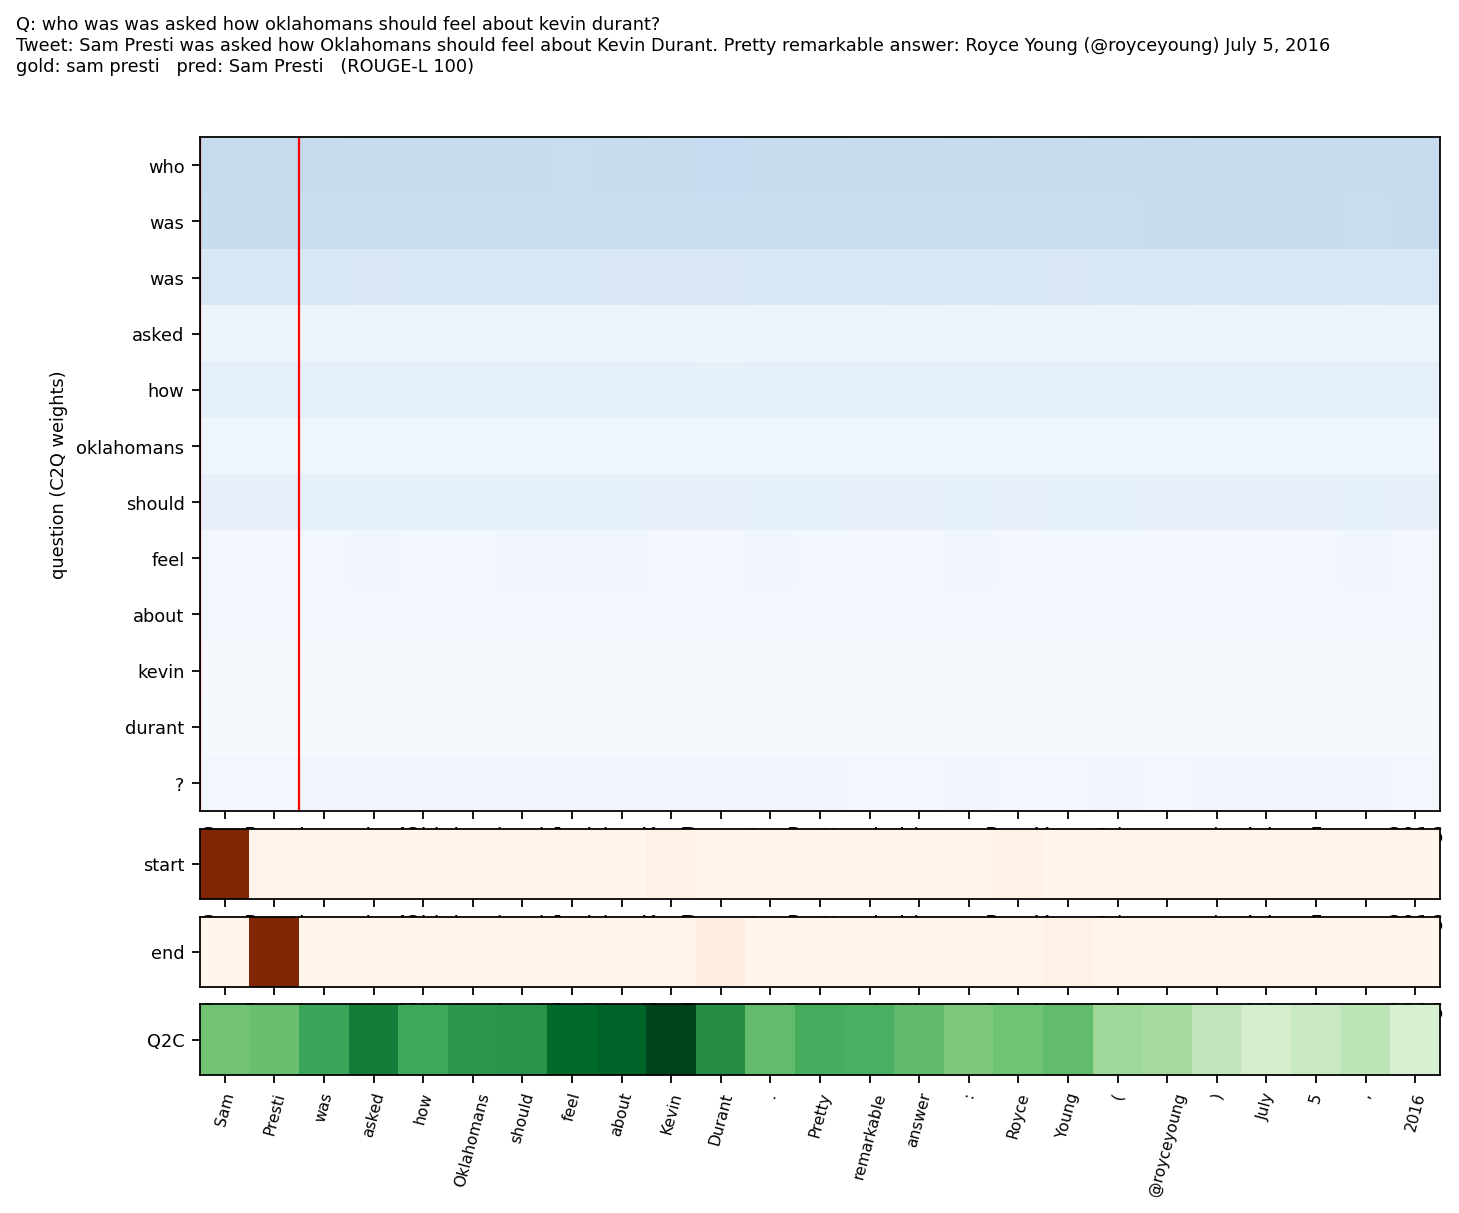

success_what


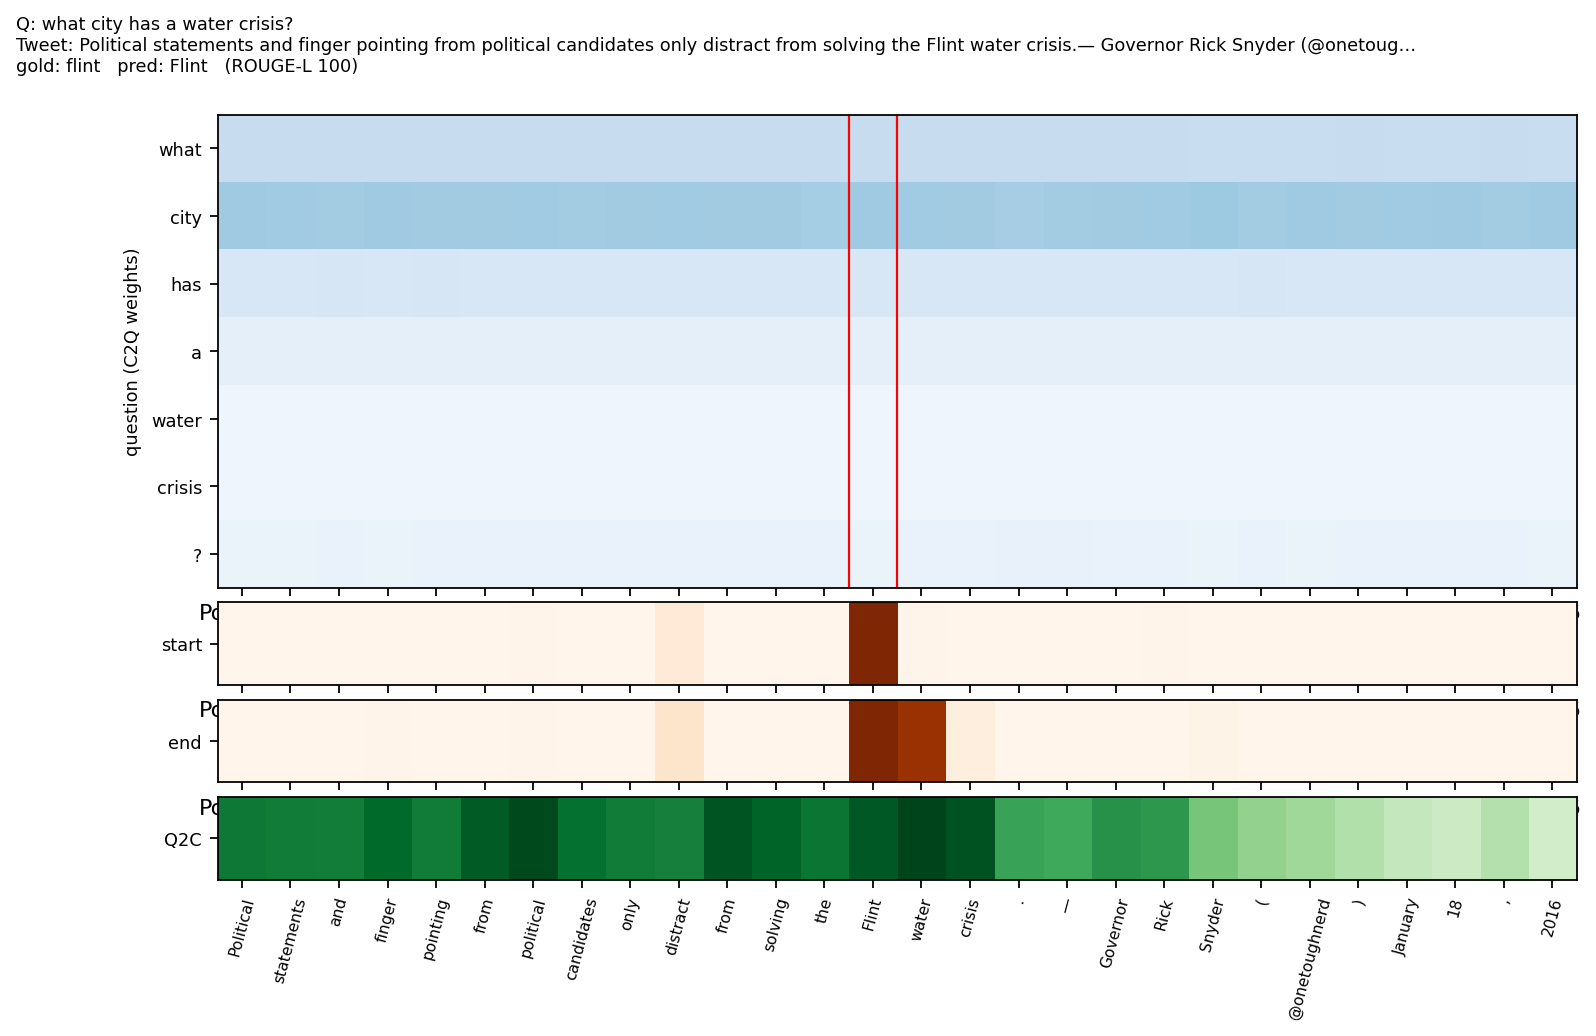

success_where


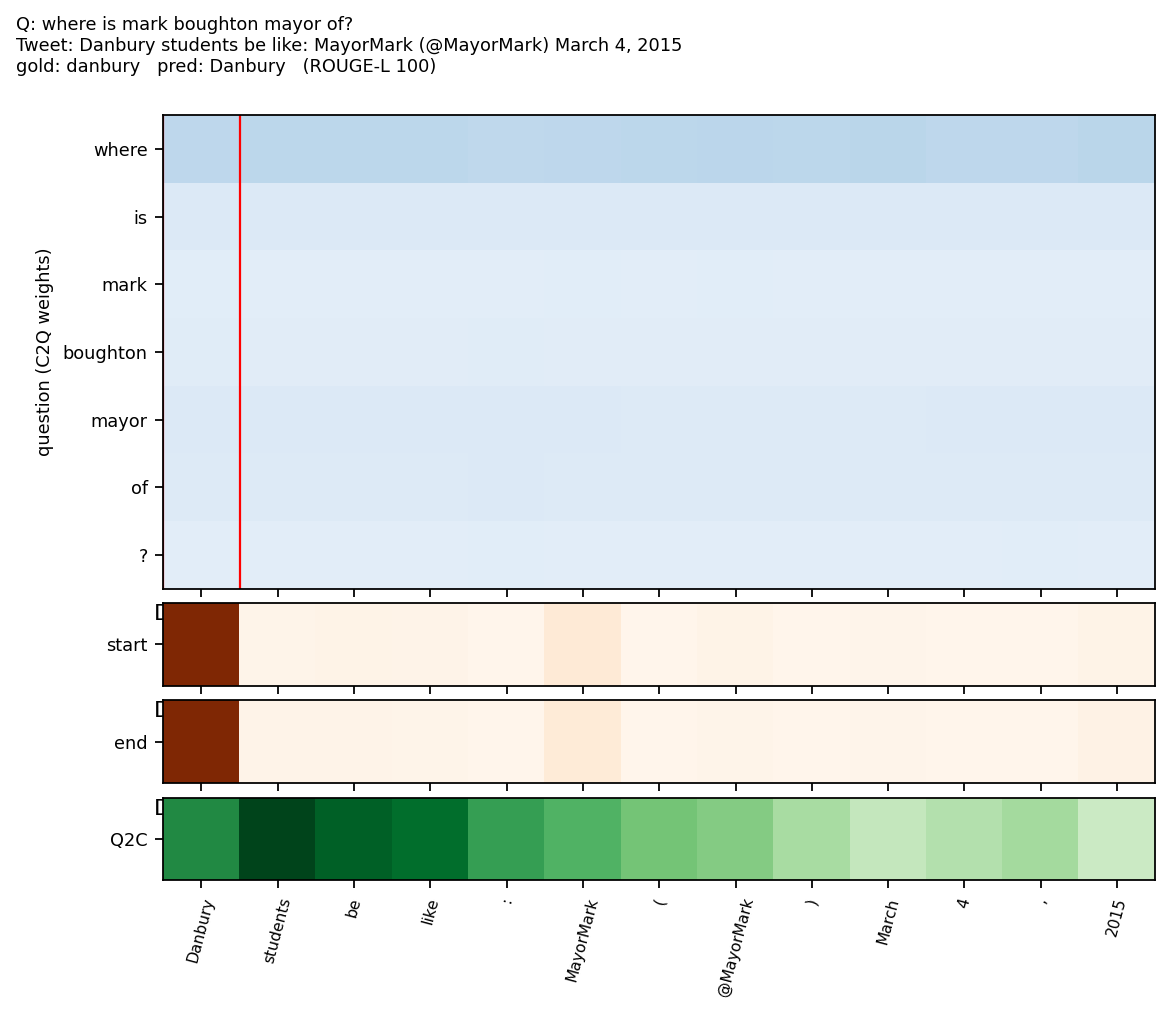

fail_username


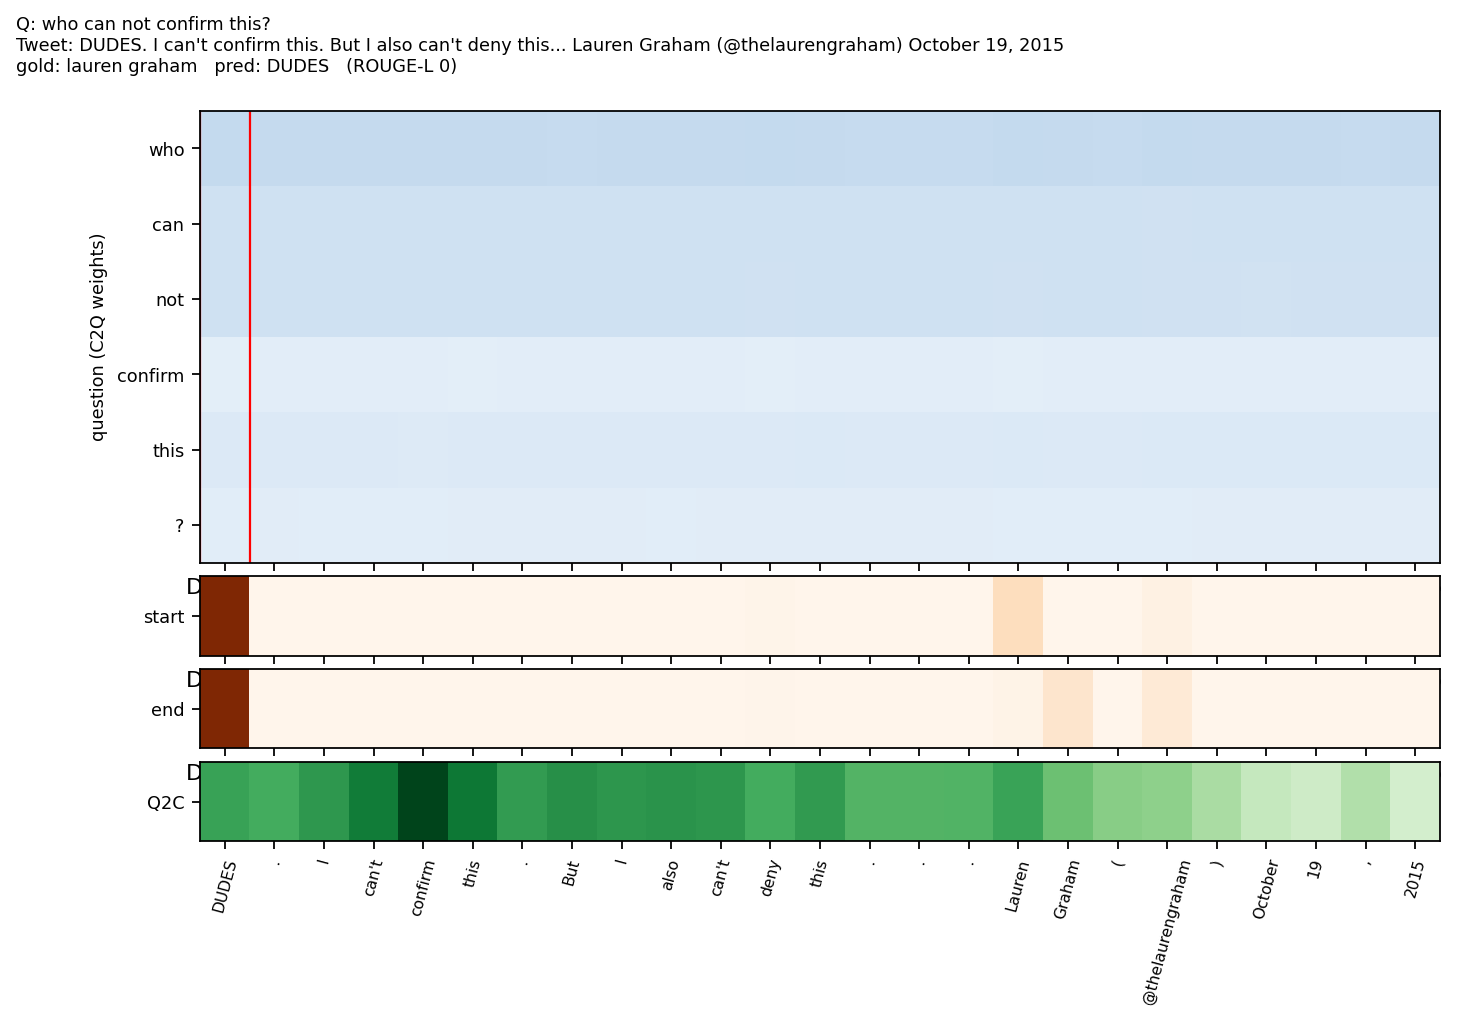

fail_abstractive


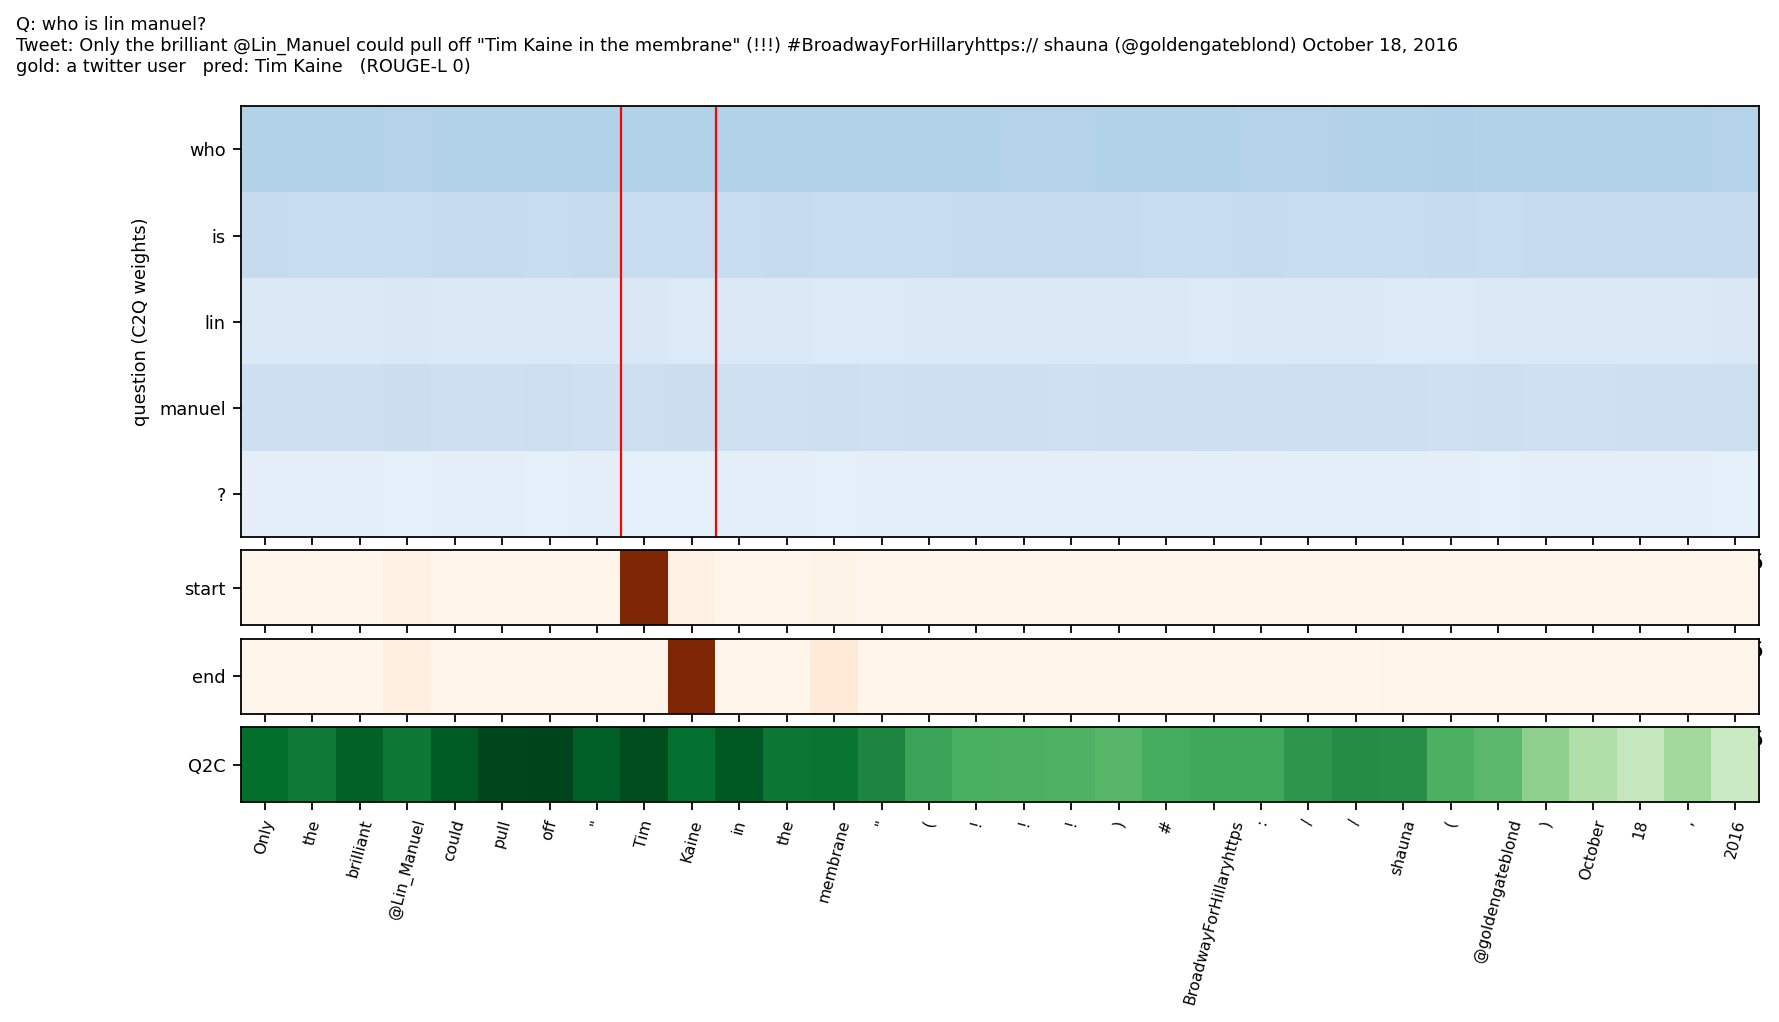

fail_slang_misspelt


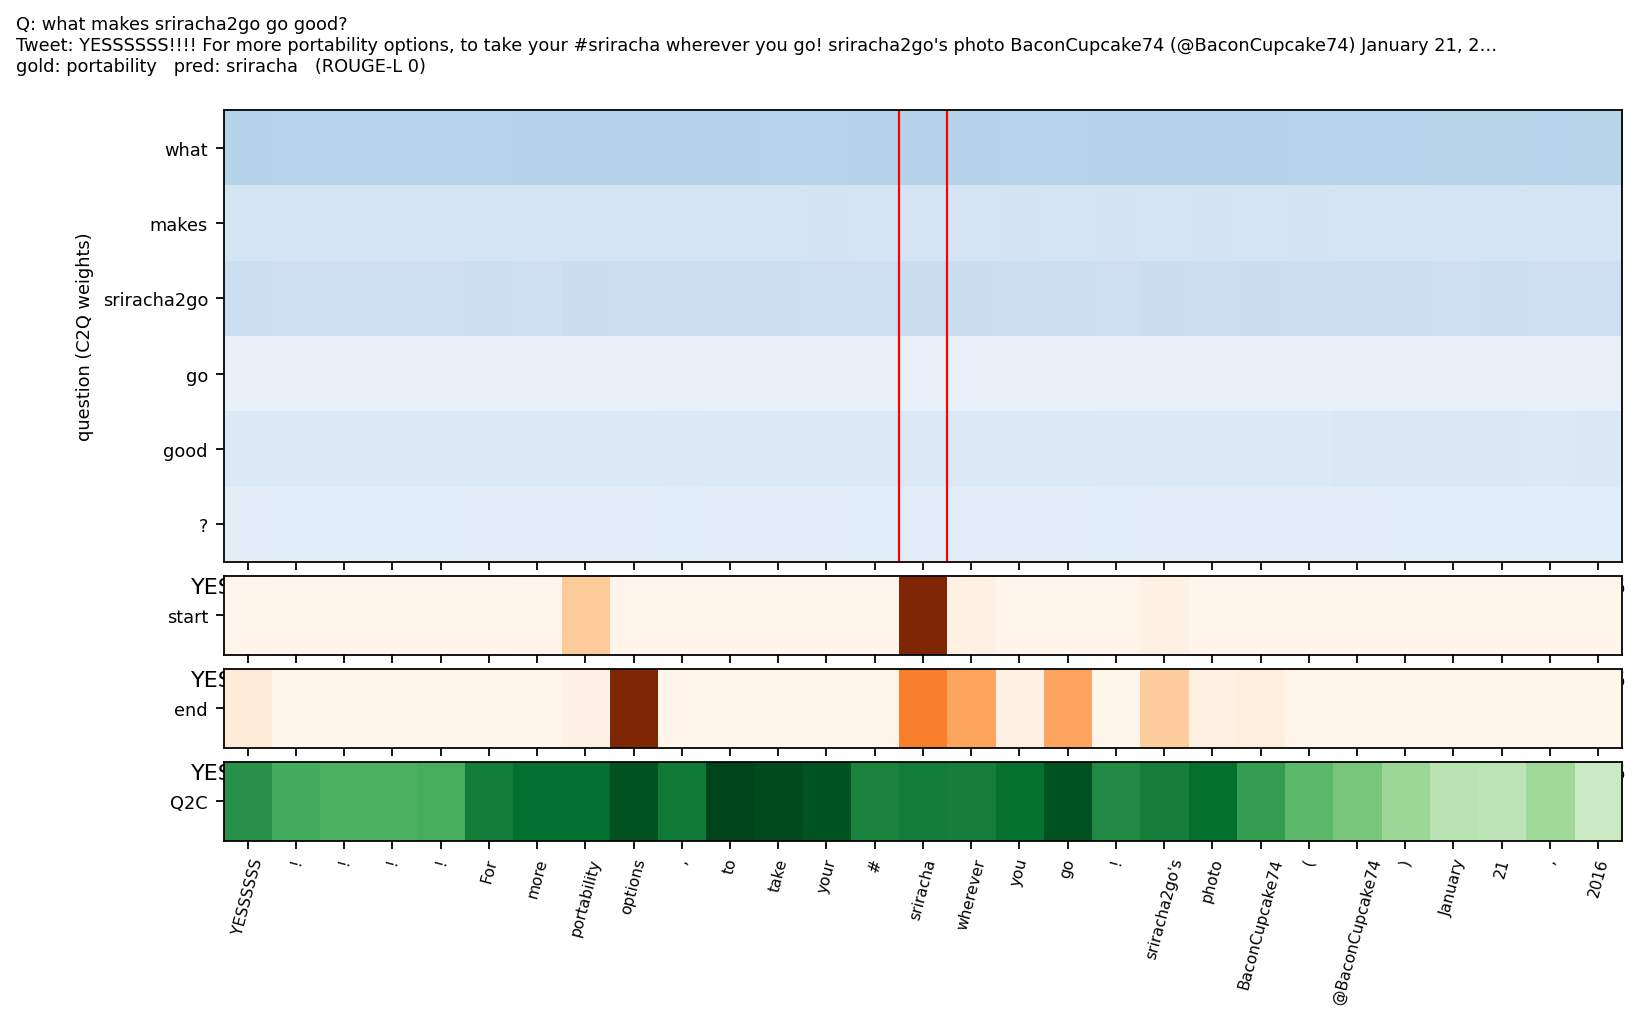

self_attn_A3


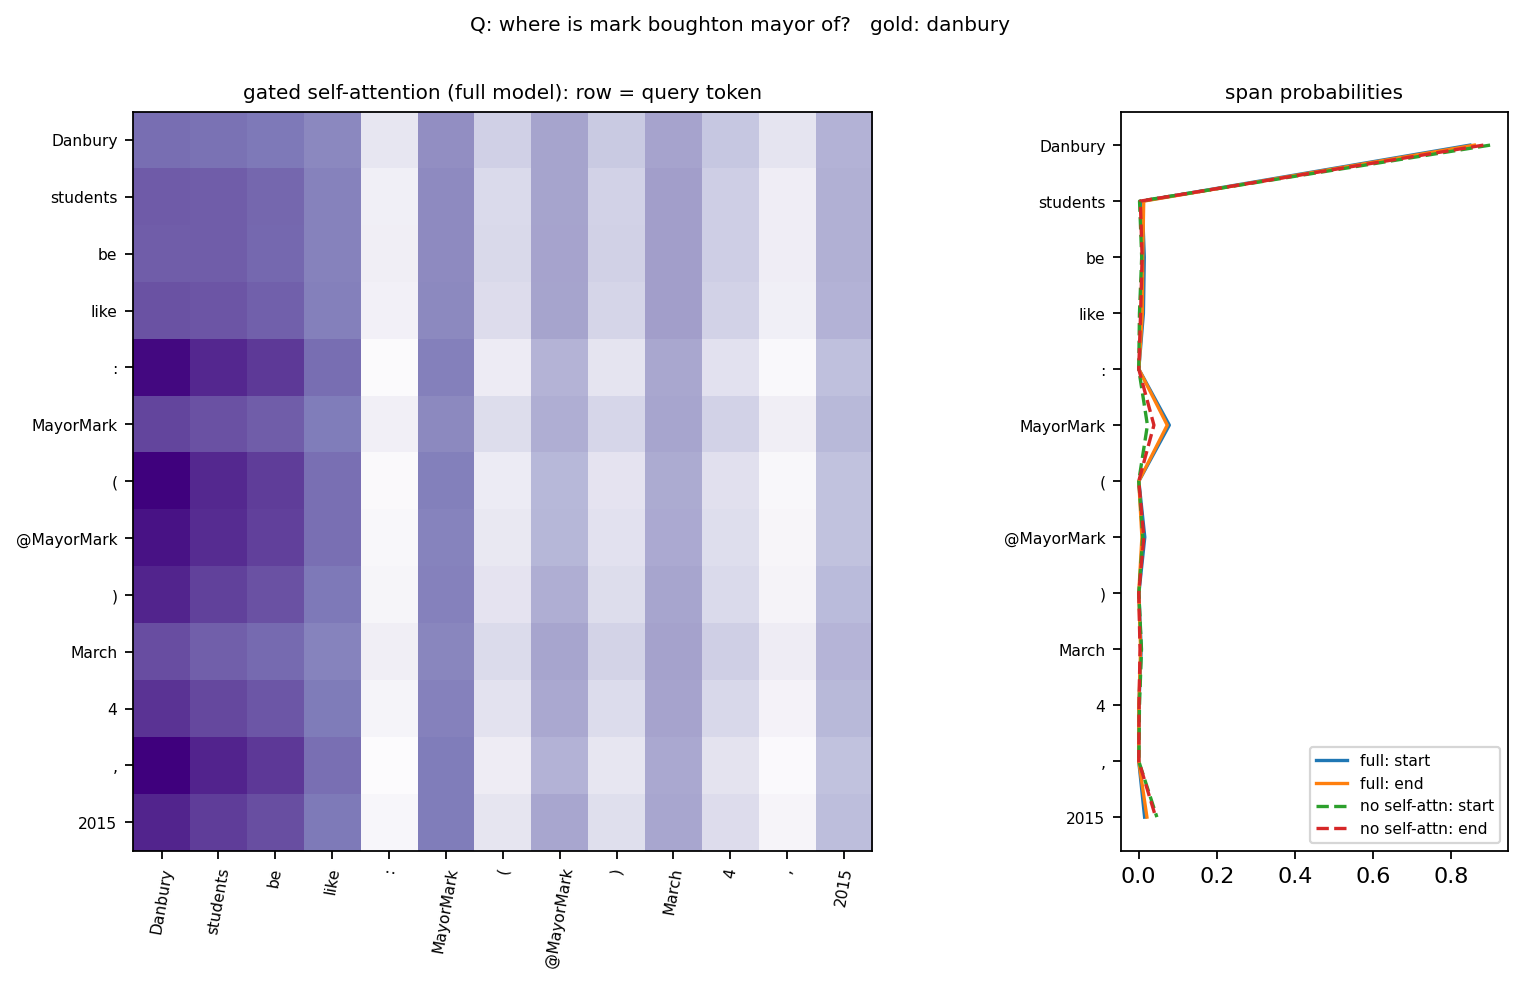

training_curves


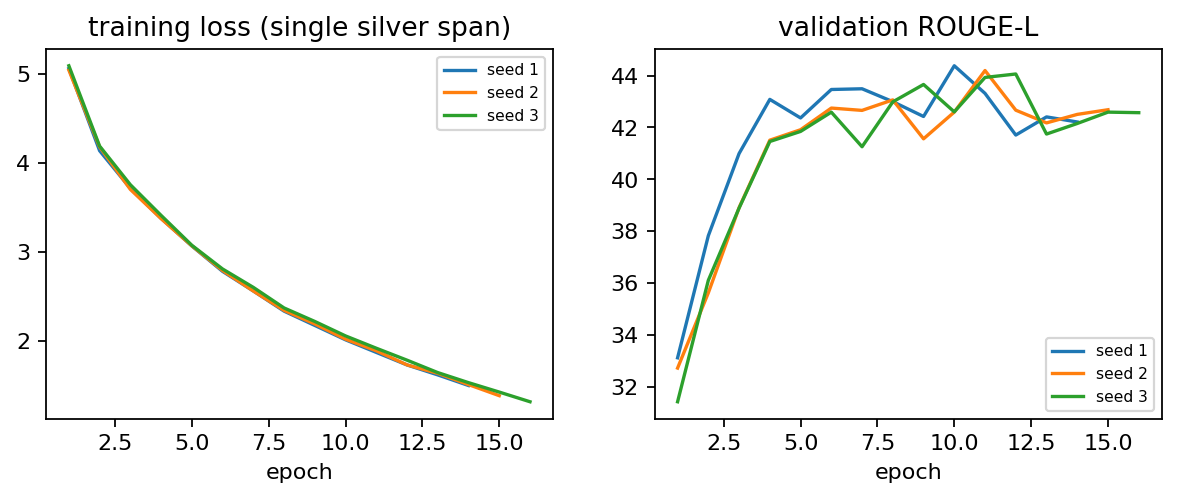

In [25]:
for name in ["success_who","success_what","success_where","fail_username","fail_abstractive","fail_slang_misspelt"]:
    print(name);display(Image(filename=f"attention/results/figures/attn_{name}.png",width=950))
for name in ["self_attn_A3","training_curves"]:
    print(name);display(Image(filename=f"attention/results/figures/{name}.png",width=950))


### Error sample
Automatically tagged validation sample; these are not claimed as manually labelled errors.

In [26]:
attention=json.loads(Path("attention/results/stage7_summary.json").read_text())
print("Analysis checkpoint:",attention["full_run"])
print("Errors (EM=0):",attention["n_errors"],"/ 1076 validation questions")
print("Automatic categories in the 100-error sample:",attention["auto_tags"])
error_rows=read_csv("attention/results/error_sample.csv")
assert len(error_rows)==100
for row in error_rows[:8]:
    print({k:v for k,v in row.items() if k in ["question","gold","pred","auto_tag","error_cause"]})
print("Question-type breakdown:")
for word,values in attention["qtype"].items():print(word,values)

Analysis checkpoint: A5_single_span-s1-20261014-071243
Errors (EM=0): 786 / 1076 validation questions
Automatic categories in the 100-error sample: {'wrong span (no overlap)': 26, 'boundary / partial overlap': 40, 'abstractive gold (no good span)': 23, 'byline vs body confusion': 11}
{'question': 'what did kallis end there?', 'gold': 'his illustrious career', 'pred': '1995 at Kingsmead', 'error_cause': '', 'auto_tag': 'wrong span (no overlap)'}
{'question': 'what is rihanna being praised for?', 'gold': 'showing what inclusive means to the makeup industry', 'pred': 'inclusive', 'error_cause': '', 'auto_tag': 'boundary / partial overlap'}
{'question': "what embassy changed it's picture to je suis charlie?", 'gold': 'france', 'pred': 'Twitter', 'error_cause': '', 'auto_tag': 'wrong span (no overlap)'}
{'question': 'who went with jimmy to a haunted house?', 'gold': 'kevin hart', 'pred': '@KevinHart4real', 'error_cause': '', 'auto_tag': 'abstractive gold (no good span)'}
{'question': 'at wh

### Optional validation inference
Disabled by default. Downloads only saved model artifacts, never implementation code. This verifies the fixed system without training or fresh test prediction.

In [27]:
if RUN_VALIDATION_INFERENCE:
    import subprocess,urllib.request
    subprocess.check_call([sys.executable,"-m","pip","install","-q","lightgbm==4.6.0","scikit-learn==1.6.1","joblib==1.6.0"])
    import joblib
    PINNED="84b85d90a997cc98632dc06a822cd42a5c19ec17"
    archives={"a2_v2_colab_artifacts.zip":"6fc46dc5ef256426d8c4b95da2898483edba34687a62013bc2889cd59c9badd4",
              "oof_span_reranker_artifacts.zip":"83436c4eff8604c8ebed3f898fab5874e5e67972097743b13389e4fcd05e4c00"}
    for name,digest in archives.items():
        p=Path(name)
        if not p.exists():
            url=f"https://raw.githubusercontent.com/James-h95/A2/{PINNED}/{name}"
            try: urllib.request.urlretrieve(url,p)
            except Exception as error:
                print("Archive download failed; upload the original",name,"Error:",error)
                from google.colab import files
                up=files.upload();assert name in up;p.write_bytes(up[name])
        assert hashlib.sha256(p.read_bytes()).hexdigest()==digest,name
    members=["checkpoints/A5_single_span-s1-20261014-071243.pt","checkpoints/A5_single_span-s2-20261014-071828.pt","checkpoints/A5_single_span-s3-20261014-072428.pt"]
    with zipfile.ZipFile("a2_v2_colab_artifacts.zip") as z:
        for name in members:
            p=Path(name);p.parent.mkdir(parents=True,exist_ok=True);p.write_bytes(z.read(name))
    member="oof_reranker_results/oof_lambdamart_reranker.joblib"
    with zipfile.ZipFile("oof_span_reranker_artifacts.zip") as z:
        p=Path(member);p.parent.mkdir(parents=True,exist_ok=True);p.write_bytes(z.read(member))
    reranker=joblib.load(member);assert reranker.n_features_in_==30
    from src.selected_inference import predict_selected_system
    outputs,_=predict_selected_system(val_rows,[Path(p) for p in members],reranker,device="cuda" if torch.cuda.is_available() else "cpu")
    reference=json.loads(Path("evidence/01_validation/validation_predictions.json").read_text())
    ref={r["row_id"]:r["prediction"] for r in reference}
    assert len(outputs)==1076 and set(ref)=={r["row_id"] for r in outputs}
    assert all(r["prediction"]==ref[r["row_id"]] for r in outputs)
    print("PASS: fresh selected-model validation inference matches 1076/1076 reference answers")
else:
    print("Fresh model inference skipped; original successful Colab validation evidence is embedded above.")

Fresh model inference skipped; original successful Colab validation evidence is embedded above.
